<a href="https://colab.research.google.com/github/binaykushwaha1244/01-Single-Tool-Calling-Agent/blob/main/Yet_another_copy_of_QSecure_finnay_Done_%E2%9C%85.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================
# CELL 1: IMPORT LIBRARIES AND UPLOAD DATASET
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
import io

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Upload CSV from your computer
print("Please select your Q-Secure dataset CSV file.")

uploaded = files.upload()

# Read uploaded CSV
if not uploaded:
    raise ValueError("No file uploaded. Please upload your dataset.")

filename = next(iter(uploaded))

if not filename.lower().endswith(".csv"):
    raise ValueError("Please upload a CSV file.")

df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Dataset information
print("\n" + "=" * 60)
print("Q-SECURE DATASET INFORMATION")
print("=" * 60)

print("\nUploaded File:", filename)
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nDataset Loaded Successfully!")

Please select your Q-Secure dataset CSV file.


Saving quantum_risk_pqc_migration_dataset.csv to quantum_risk_pqc_migration_dataset.csv

Q-SECURE DATASET INFORMATION

Uploaded File: quantum_risk_pqc_migration_dataset.csv
Dataset Shape: (20000, 35)

First 5 Rows:


,Asset_ID,Asset_Name,Asset_Type,Business_Unit,Environment,Cloud_Provider,Region,Operating_System,Current_Cryptographic_Algorithm,Current_Key_Size,Crypto_Purpose,Certificate_Age_Days,Certificate_Expiry_Days,Internet_Facing,Criticality,Business_Impact,Data_Sensitivity,Compliance,Dependency_Count,Blast_Radius,Daily_Connections,Daily_Transactions,Confidentiality_Lifetime_Years,Legacy_System,Performance_Constraint,Migration_Complexity,Team_Readiness,Historical_Security_Incidents,Historical_Upgrade_Success_Rate,Estimated_Downtime_Hours,Estimated_Migration_Cost_USD,Quantum_Risk_Score,Recommended_PQC_Algorithm,Migration_Priority,Estimated_Migration_Duration_Days
0,AST-014357,tls-cert-engineering-635,TLS Certificate,Engineering,Production,AWS,us-east-1,Linux (Ubuntu),ECDSA,384,TLS,51.0,474.0,No,Low,Low,Internal,NaN,15.0,Low,103.0,15.0,3,Yes,Low,High,Low,1.0,0.73,11.6,44680,46.4,ML-KEM,Medium,31.3
1,AST-003440,codesign-customersupport-949,Code Signing Server,Customer Support,Production,AWS,sa-east-1,CoreOS,RSA-4096,4096,Code Signing,465.0,288.0,No,High,Medium,Confidential,PCI-DSS,23.0,High,5672.0,3270.0,12,No,Low,High,Medium,1.0,0.76,3.2,57206,76.4,ML-DSA,Immediate,19.2
2,AST-012154,k8s-retail-867,Kubernetes Cluster,Retail,Production,Azure,ap-south-1,Linux (RHEL),RSA-3072,3072,TLS,417.0,93.0,No,High,High,Confidential,GDPR,26.0,Medium,1590.0,700.0,9,No,Medium,High,Medium,2.0,0.77,12.8,60133,71.7,ML-KEM,High,21.5
3,AST-015030,reg-retail-294,Container Registry,Retail,Production,GCP,ap-southeast-1,Network Appliance OS,RSA-2048,2048,TLS,229.0,263.0,No,Low,NaN,Internal,NaN,3.0,Low,538.0,395.0,8,No,Low,Low,Medium,1.0,0.73,2.5,15833,39.3,ML-KEM,Medium,3.4
4,AST-018550,storage-engineering-742,File Storage,Engineering,Production,Azure,ap-south-1,Linux (RHEL),AES-256,256,Data-at-Rest,538.0,136.0,No,Medium,High,Internal,ISO27001,15.0,Medium,282.0,NaN,1,Yes,Low,Medium,Low,1.0,0.63,2.5,44965,33.3,No Change,Low,17.4



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Asset_ID                           20000 non-null  object 
 1   Asset_Name                         20000 non-null  object 
 2   Asset_Type                         20000 non-null  object 
 3   Business_Unit                      20000 non-null  object 
 4   Environment                        20000 non-null  object 
 5   Cloud_Provider                     20000 non-null  object 
 6   Region                             19158 non-null  object 
 7   Operating_System                   19240 non-null  object 
 8   Current_Cryptographic_Algorithm    20000 non-null  object 
 9   Current_Key_Size                   20000 non-null  int64  
 10  Crypto_Purpose                     20000 non-null  object 
 11  Certificate_Age_Days            

## A. Understand the data types and missing values.

In [2]:
# ============================================
# CELL 2: DATA QUALITY ANALYSIS
# ============================================

# Check data types and non-null counts
df.info()

# Missing value analysis
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values = missing_values[
    missing_values["Missing_Count"] > 0
].sort_values(by="Missing_Count", ascending=False)

print("\nMissing Value Analysis:")
display(missing_values)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Asset_ID                           20000 non-null  object 
 1   Asset_Name                         20000 non-null  object 
 2   Asset_Type                         20000 non-null  object 
 3   Business_Unit                      20000 non-null  object 
 4   Environment                        20000 non-null  object 
 5   Cloud_Provider                     20000 non-null  object 
 6   Region                             19158 non-null  object 
 7   Operating_System                   19240 non-null  object 
 8   Current_Cryptographic_Algorithm    20000 non-null  object 
 9   Current_Key_Size                   20000 non-null  int64  
 10  Crypto_Purpose                     20000 non-null  object 
 11  Certificate_Age_Days               19216 non-null  flo

,Missing_Count,Missing_Percentage
Compliance,8243,41.22
Region,842,4.21
Dependency_Count,820,4.10
Team_Readiness,804,4.02
Certificate_Age_Days,784,3.92
Operating_System,760,3.80
Performance_Constraint,720,3.60
Estimated_Downtime_Hours,685,3.42
Business_Impact,633,3.16
Daily_Transactions,592,2.96


In [3]:
print("Duplicate Asset_IDs:", df["Asset_ID"].duplicated().sum())

Duplicate Asset_IDs: 0


##

## B. Data Cleaning

In [4]:
# ============================================
# CELL: CLEAN ENVIRONMENT AND CLOUD PROVIDER
# ============================================

# Clean Environment
df["Environment"] = (
    df["Environment"]
    .str.strip()
    .str.lower()
    .str.capitalize()
)

# Clean Cloud Provider
df["Cloud_Provider"] = (
    df["Cloud_Provider"]
    .str.strip()
    .str.lower()
    .replace({
        "aws": "AWS",
        "azure": "Azure",
        "gcp": "GCP",
        "on-prem": "On-Prem"
    })
)

# Verify cleaned values
print("Environment Categories:")
print(df["Environment"].value_counts(dropna=False))

print("\nCloud Provider Categories:")
print(df["Cloud_Provider"].value_counts(dropna=False))

print("\nMissing values after cleaning:")
print(df[["Environment", "Cloud_Provider"]].isnull().sum())

Environment Categories:
Environment
Production     12037
Staging         4930
Development     3033
Name: count, dtype: int64

Cloud Provider Categories:
Cloud_Provider
AWS        8034
Azure      5538
GCP        4008
On-Prem    2420
Name: count, dtype: int64

Missing values after cleaning:
Environment       0
Cloud_Provider    0
dtype: int64


## C. Drop unnecessary columns


In [5]:
# Columns that should not be used as ML features
drop_columns = [
    "Asset_ID",
    "Asset_Name"
]

# Create a new dataframe without these columns
df_clean = df.drop(columns=drop_columns)

print("Original shape:", df.shape)
print("Shape after dropping columns:", df_clean.shape)

print("\nRemaining columns:")
print(df_clean.columns.tolist())

Original shape: (20000, 35)
Shape after dropping columns: (20000, 33)

Remaining columns:
['Asset_Type', 'Business_Unit', 'Environment', 'Cloud_Provider', 'Region', 'Operating_System', 'Current_Cryptographic_Algorithm', 'Current_Key_Size', 'Crypto_Purpose', 'Certificate_Age_Days', 'Certificate_Expiry_Days', 'Internet_Facing', 'Criticality', 'Business_Impact', 'Data_Sensitivity', 'Compliance', 'Dependency_Count', 'Blast_Radius', 'Daily_Connections', 'Daily_Transactions', 'Confidentiality_Lifetime_Years', 'Legacy_System', 'Performance_Constraint', 'Migration_Complexity', 'Team_Readiness', 'Historical_Security_Incidents', 'Historical_Upgrade_Success_Rate', 'Estimated_Downtime_Hours', 'Estimated_Migration_Cost_USD', 'Quantum_Risk_Score', 'Recommended_PQC_Algorithm', 'Migration_Priority', 'Estimated_Migration_Duration_Days']


## D. Separating Target Columns

In [6]:
target_columns = [
    "Quantum_Risk_Score",
    "Recommended_PQC_Algorithm",
    "Migration_Priority",
    "Estimated_Migration_Duration_Days"
]

# Verify target columns
for col in target_columns:
    assert col in df_clean.columns, f"Missing target column: {col}"

print("All four target columns are present.")

All four target columns are present.


## E. Feature Classification

In [7]:

all_columns = df_clean.columns.tolist()
feature_columns = [col for col in all_columns if col not in target_columns]

numerical_features = df_clean[feature_columns].select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = df_clean[feature_columns].select_dtypes(include="object").columns.tolist()

# ============================================
# FEATURE TYPE VALIDATION
# ============================================

print("Total Features:", len(feature_columns))
print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

# Validation
assert len(feature_columns) == 29
assert len(numerical_features) + len(categorical_features) == 29
assert not set(feature_columns).intersection(target_columns)

print("\nFeature separation verified successfully!")

Total Features: 29
Numerical Features: 11
Categorical Features: 18

Numerical Features:
['Current_Key_Size', 'Certificate_Age_Days', 'Certificate_Expiry_Days', 'Dependency_Count', 'Daily_Connections', 'Daily_Transactions', 'Confidentiality_Lifetime_Years', 'Historical_Security_Incidents', 'Historical_Upgrade_Success_Rate', 'Estimated_Downtime_Hours', 'Estimated_Migration_Cost_USD']

Categorical Features:
['Asset_Type', 'Business_Unit', 'Environment', 'Cloud_Provider', 'Region', 'Operating_System', 'Current_Cryptographic_Algorithm', 'Crypto_Purpose', 'Internet_Facing', 'Criticality', 'Business_Impact', 'Data_Sensitivity', 'Compliance', 'Blast_Radius', 'Legacy_System', 'Performance_Constraint', 'Migration_Complexity', 'Team_Readiness']

Feature separation verified successfully!


### F. Correlation Analysis


CORRELATION ANALYSIS

 No highly correlated features found.


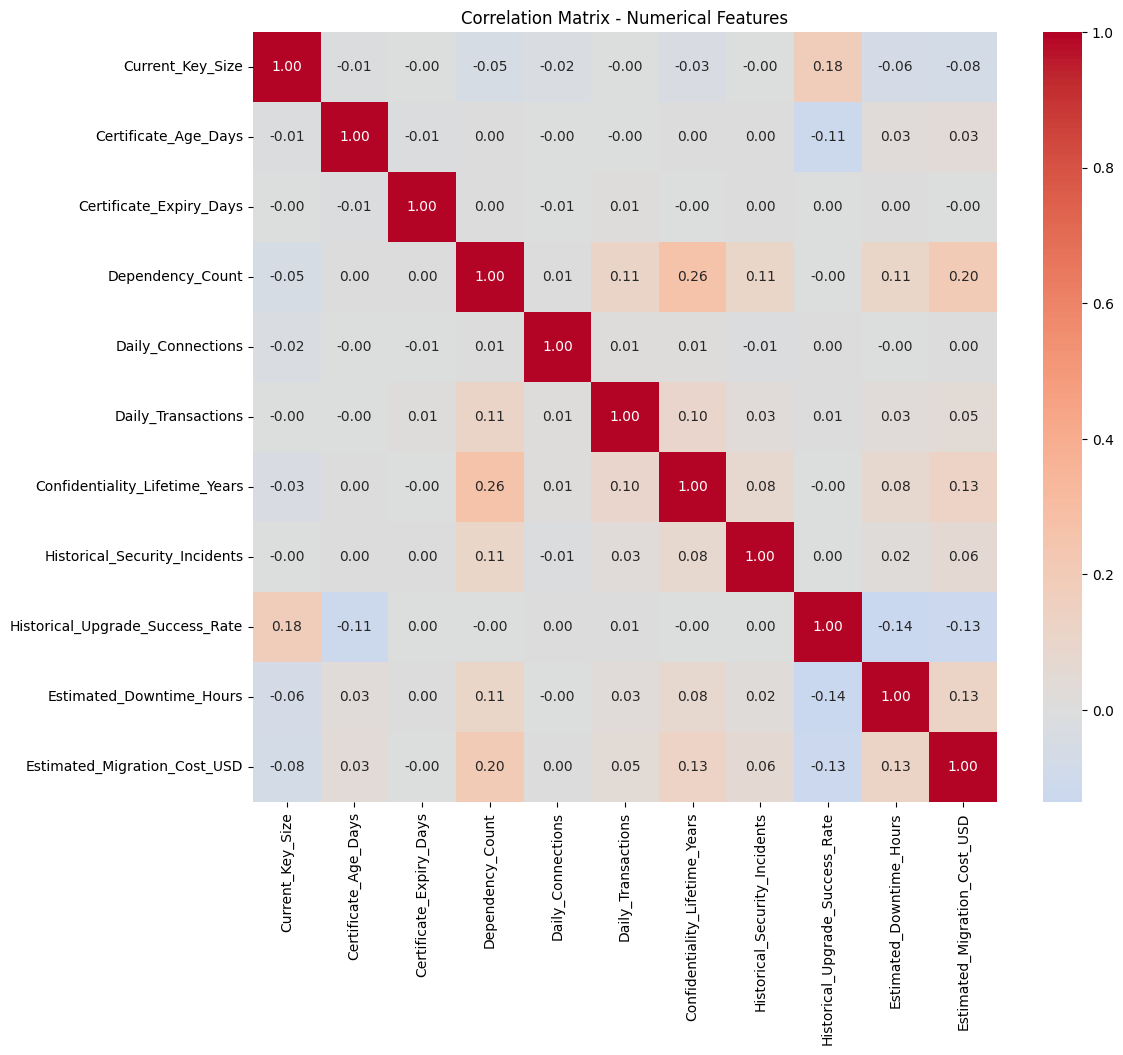

In [8]:
print("\n" + "="*60)
print("CORRELATION ANALYSIS")
print("="*60)

corr_matrix = df_clean[numerical_features].corr()

# Find highly correlated features (>0.85)
high_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.85:
            high_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

if high_corr:
    print("\nHighly Correlated Features (>0.85):")
    for feat1, feat2, corr in high_corr:
        print(f"  {feat1} ↔ {feat2}: {corr:.3f}")
else:
    print("\n No highly correlated features found.")

# Visualize
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Matrix - Numerical Features')
plt.show()


 Since , no such highly correlation so, lets apply few other appraoches for feature selection

### Correlation with target


CORRELATION ANALYSIS


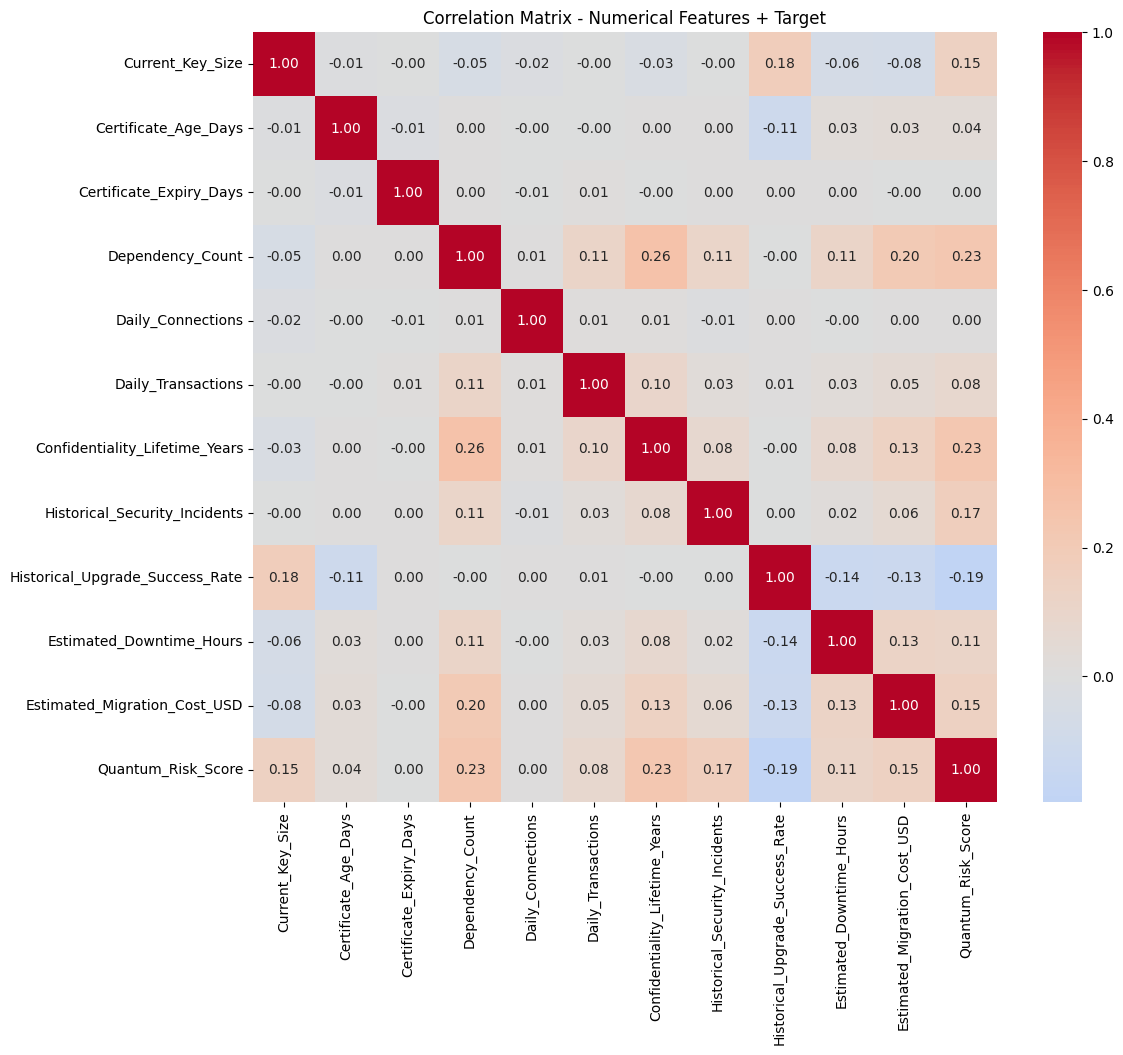


Correlation with Quantum_Risk_Score (sorted):
                                 Quantum_Risk_Score
Confidentiality_Lifetime_Years             0.232817
Dependency_Count                           0.226946
Historical_Security_Incidents              0.167661
Estimated_Migration_Cost_USD               0.150257
Current_Key_Size                           0.148918
Estimated_Downtime_Hours                   0.110220
Daily_Transactions                         0.081596
Certificate_Age_Days                       0.037539
Daily_Connections                          0.002289
Certificate_Expiry_Days                    0.000702
Historical_Upgrade_Success_Rate           -0.194994


In [9]:
print("\n" + "="*60)
print("CORRELATION ANALYSIS")
print("="*60)

target_col = "Quantum_Risk_Score"
cols_for_corr = numerical_features + [target_col] if target_col not in numerical_features else numerical_features
corr_matrix = df_clean[cols_for_corr].corr()

# Visualize full correlation matrix (features + target)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Matrix - Numerical Features + Target')
plt.show()

# Clearly show which features matter most for the target
print(f"\nCorrelation with {target_col} (sorted):")
target_corr = corr_matrix[[target_col]].drop(index=target_col).sort_values(by=target_col, ascending=False)
print(target_corr)

### G.Basic Feature Engineering

In [10]:
# ============================================
# FEATURE ENGINEERING
# ============================================

print("FEATURE ENGINEERING")
print("=" * 60)

# 1. Business Impact Score
impact_map = {
    "Low": 1,
    "Medium": 2,
    "High": 3
}

df_clean["Business_Impact_Score"] = (
    df_clean["Business_Impact"].map(impact_map)
)

print("Business_Impact_Score created")


# 2. Incident Rate
df_clean["Incident_Rate"] = (
    df_clean["Historical_Security_Incidents"]
    / (df_clean["Confidentiality_Lifetime_Years"] + 1)
)

print("Incident_Rate created")


# 3. Upgrade Failure Rate
df_clean["Upgrade_Failure_Rate"] = (
    1 - df_clean["Historical_Upgrade_Success_Rate"]
)

print("Upgrade_Failure_Rate created")


# 4. Cost Per Downtime Hour
# Preserve missing values and avoid division by zero.
df_clean["Cost_Per_Hour"] = np.where(
    df_clean["Estimated_Downtime_Hours"] > 0,
    df_clean["Estimated_Migration_Cost_USD"] /
    df_clean["Estimated_Downtime_Hours"],
    np.nan
)

print("Cost_Per_Hour created")


# ============================================
# UPDATE FEATURE LISTS
# ============================================

if "Business_Impact" in categorical_features:
    categorical_features.remove("Business_Impact")

if "Business_Impact_Score" not in numerical_features:
    numerical_features.append("Business_Impact_Score")

new_features = [
    "Incident_Rate",
    "Upgrade_Failure_Rate",
    "Cost_Per_Hour"
]

for feature in new_features:
    if feature not in numerical_features:
        numerical_features.append(feature)


# ============================================
# FINAL FEATURE LIST
# ============================================

# Remove Strong_Key from previous execution
if "Strong_Key" in numerical_features:
    numerical_features.remove("Strong_Key")

# Remove the old engineered column from the dataframe
if "Strong_Key" in df_clean.columns:
    df_clean.drop(columns=["Strong_Key"], inplace=True)

feature_columns = numerical_features + categorical_features

print("\n" + "=" * 60)
print("FINAL FEATURES AFTER FEATURE ENGINEERING")
print("=" * 60)

print("\nNumerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))
print("Total Features:", len(feature_columns))

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

# Validation
assert len(feature_columns) == len(set(feature_columns))
assert not set(feature_columns).intersection(target_columns)
assert "Strong_Key" not in feature_columns

print("\nFeature engineering completed successfully!")

FEATURE ENGINEERING
Business_Impact_Score created
Incident_Rate created
Upgrade_Failure_Rate created
Cost_Per_Hour created

FINAL FEATURES AFTER FEATURE ENGINEERING

Numerical Features: 15
Categorical Features: 17
Total Features: 32

Numerical Features:
['Current_Key_Size', 'Certificate_Age_Days', 'Certificate_Expiry_Days', 'Dependency_Count', 'Daily_Connections', 'Daily_Transactions', 'Confidentiality_Lifetime_Years', 'Historical_Security_Incidents', 'Historical_Upgrade_Success_Rate', 'Estimated_Downtime_Hours', 'Estimated_Migration_Cost_USD', 'Business_Impact_Score', 'Incident_Rate', 'Upgrade_Failure_Rate', 'Cost_Per_Hour']

Categorical Features:
['Asset_Type', 'Business_Unit', 'Environment', 'Cloud_Provider', 'Region', 'Operating_System', 'Current_Cryptographic_Algorithm', 'Crypto_Purpose', 'Internet_Facing', 'Criticality', 'Data_Sensitivity', 'Compliance', 'Blast_Radius', 'Legacy_System', 'Performance_Constraint', 'Migration_Complexity', 'Team_Readiness']

Feature engineering compl

### H.  Train/Validation/Test Split1

In [11]:
# ============================================
# TRAIN / VALIDATION / TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

print("\n" + "=" * 60)
print("TRAIN / VALIDATION / TEST SPLIT")
print("=" * 60)

# Define features
X = df_clean[feature_columns].copy()

# Define all four target variables
Y = df_clean[target_columns].copy()

# First split: 70% training, 30% temporary
X_train, X_temp, Y_train, Y_temp = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42
)

# Second split: 15% validation, 15% test
X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp,
    Y_temp,
    test_size=0.50,
    random_state=42
)

# Extract individual targets while preserving row indices
y_train = Y_train["Quantum_Risk_Score"]
y_val = Y_val["Quantum_Risk_Score"]
y_test = Y_test["Quantum_Risk_Score"]

# Display split sizes
print("\nDataset sizes:")
print(f"Total      : {len(X)}")
print(f"Training   : {len(X_train)}")
print(f"Validation : {len(X_val)}")
print(f"Test       : {len(X_test)}")

print("\nSplit percentages:")
print(f"Training   : {len(X_train)/len(X)*100:.1f}%")
print(f"Validation : {len(X_val)/len(X)*100:.1f}%")
print(f"Test       : {len(X_test)/len(X)*100:.1f}%")

# Verify all four targets are aligned
assert X_train.index.equals(Y_train.index)
assert X_val.index.equals(Y_val.index)
assert X_test.index.equals(Y_test.index)

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

print("\nAll four targets share identical data partitions.")
print("No train-validation-test overlap detected.")


TRAIN / VALIDATION / TEST SPLIT

Dataset sizes:
Total      : 20000
Training   : 14000
Validation : 3000
Test       : 3000

Split percentages:
Training   : 70.0%
Validation : 15.0%
Test       : 15.0%

All four targets share identical data partitions.
No train-validation-test overlap detected.


###  I. Feature Selection using Anova for 'Risk Score'

In [12]:
# ============================================
# RISK MODEL: FEATURE SELECTION
# ============================================
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, KBinsDiscretizer
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import f_classif
from sklearn.pipeline import Pipeline  # ADD THIS

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, KBinsDiscretizer
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import f_classif
import numpy as np
import pandas as pd

print("\n" + "=" * 60)
print("QUANTUM RISK FEATURE SELECTION")
print("=" * 60)

# Preserve original feature lists
risk_numerical_features = numerical_features.copy()
risk_categorical_features = categorical_features.copy()
risk_all_features = feature_columns.copy()

# 1. Prepare training-only preprocessing
risk_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            risk_numerical_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="constant",
                    fill_value="Unknown"
                )),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            risk_categorical_features
        )
    ],
    remainder="drop"
)

# Import Pipeline
from sklearn.pipeline import Pipeline

# 2. Fit preprocessing only on training data
X_train_risk_encoded = risk_preprocessor.fit_transform(
    X_train[risk_all_features]
)

# Convert sparse matrix if necessary
if hasattr(X_train_risk_encoded, "toarray"):
    X_train_risk_encoded = X_train_risk_encoded.toarray()

# 3. Obtain encoded feature names
encoded_feature_names = (
    risk_preprocessor.get_feature_names_out()
)

# 4. Bin continuous risk target using training data
risk_discretizer = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="quantile"
)

y_train_risk_binned = risk_discretizer.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# 5. ANOVA feature scoring
f_scores, p_values = f_classif(
    X_train_risk_encoded,
    y_train_risk_binned
)

# 6. Map encoded columns back to original features
encoded_results = pd.DataFrame({
    "encoded_feature": encoded_feature_names,
    "f_score": f_scores,
    "p_value": p_values
})

def get_original_feature(encoded_name):
    name = encoded_name.split("__", 1)[-1]

    for col in sorted(risk_all_features, key=len, reverse=True):
        if name == col or name.startswith(col + "_"):
            return col

    return name

encoded_results["original_feature"] = (
    encoded_results["encoded_feature"].apply(
        get_original_feature
    )
)

# Aggregate one-hot scores at original feature level
results = (
    encoded_results.groupby("original_feature")
    .agg(
        f_score=("f_score", "max"),
        p_value=("p_value", "min")
    )
    .reset_index()
    .rename(columns={"original_feature": "feature"})
    .sort_values("f_score", ascending=False)
)

print("\nTOP 20 FEATURES")
print("-" * 60)

for rank, (_, row) in enumerate(results.head(20).iterrows(), 1):
    significance = (
        "SIGNIFICANT" if row["p_value"] < 0.05 else "NOT SIG"
    )

    print(
        f"{rank:2}. {row['feature']:<35} "
        f"F={row['f_score']:10.2f}  {significance}"
    )

# 7. Store ranking separately
risk_ranked_features = results["feature"].tolist()

# Provisional top-20 selection
risk_selected_features = risk_ranked_features[:20]

print("\nSelected Features:", len(risk_selected_features))
print("\nFeature ranking completed successfully.")

print("\nIMPORTANT: This is a provisional training-set ranking.")
print("Final selection must be refitted inside each CV training fold.")


QUANTUM RISK FEATURE SELECTION

TOP 20 FEATURES
------------------------------------------------------------
 1. Crypto_Purpose                      F=   2053.47  SIGNIFICANT
 2. Criticality                         F=   1209.14  SIGNIFICANT
 3. Internet_Facing                     F=   1052.47  SIGNIFICANT
 4. Current_Cryptographic_Algorithm     F=    846.05  SIGNIFICANT
 5. Data_Sensitivity                    F=    834.50  SIGNIFICANT
 6. Blast_Radius                        F=    780.08  SIGNIFICANT
 7. Asset_Type                          F=    677.38  SIGNIFICANT
 8. Business_Impact_Score               F=    599.33  SIGNIFICANT
 9. Migration_Complexity                F=    503.83  SIGNIFICANT
10. Performance_Constraint              F=    343.09  SIGNIFICANT
11. Dependency_Count                    F=    320.81  SIGNIFICANT
12. Confidentiality_Lifetime_Years      F=    303.98  SIGNIFICANT
13. Business_Unit                       F=    294.60  SIGNIFICANT
14. Legacy_System               

### J. Oultier Detection and Handling and Visualization for 'Quantum Risk Score'

In [13]:
# ============================================================
# OUTLIER CAPPING USING IQR
# ============================================================

print("=" * 60)
print("OUTLIER CAPPING")
print("=" * 60)

# Only numerical features selected for risk prediction
risk_outlier_features = [
    col for col in numerical_features
    if col in risk_selected_features
    and col not in ["Current_Key_Size", "Business_Impact_Score"]
]

# ------------------------------------------------------------
# 1. Calculate thresholds using training data
# ------------------------------------------------------------

def get_outlier_thresholds(data, features):

    thresholds = {}

    for col in features:

        values = data[col].dropna()

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        non_negative_features = [
            "Current_Key_Size",
            "Certificate_Age_Days",
            "Dependency_Count",
            "Daily_Connections",
            "Daily_Transactions",
            "Confidentiality_Lifetime_Years",
            "Historical_Security_Incidents",
            "Estimated_Downtime_Hours",
            "Estimated_Migration_Cost_USD",
            "Incident_Rate",
            "Cost_Per_Hour"
        ]

        if col in non_negative_features:
            lower = max(0, lower)

        if col in [
            "Historical_Upgrade_Success_Rate",
            "Upgrade_Failure_Rate"
        ]:
            lower = max(0, lower)
            upper = min(1, upper)

        thresholds[col] = {
            "lower": lower,
            "upper": upper
        }

    return thresholds


# ------------------------------------------------------------
# 2. Apply learned thresholds
# ------------------------------------------------------------

def cap_outliers(data, thresholds, features):

    capped = data.copy()

    for col in features:

        lower = thresholds[col]["lower"]
        upper = thresholds[col]["upper"]

        capped[col] = capped[col].clip(
            lower=lower,
            upper=upper
        )

    return capped


# ------------------------------------------------------------
# 3. Use existing train/validation/test splits
# ------------------------------------------------------------

X_train_selected = X_train[risk_selected_features].copy()
X_val_selected = X_val[risk_selected_features].copy()
X_test_selected = X_test[risk_selected_features].copy()

# Learn thresholds from training data only
thresholds = get_outlier_thresholds(
    X_train_selected,
    risk_outlier_features
)

print("\nLearned thresholds:")

for col, values in thresholds.items():

    print(
        f"{col}: "
        f"[{values['lower']:.3f}, "
        f"{values['upper']:.3f}]"
    )


# ------------------------------------------------------------
# 4. Apply thresholds to all partitions
# ------------------------------------------------------------

X_train_capped = cap_outliers(
    X_train_selected,
    thresholds,
    risk_outlier_features
)

X_val_capped = cap_outliers(
    X_val_selected,
    thresholds,
    risk_outlier_features
)

X_test_capped = cap_outliers(
    X_test_selected,
    thresholds,
    risk_outlier_features
)


# ------------------------------------------------------------
# 5. Validation
# ------------------------------------------------------------

assert X_train_capped.shape == X_train_selected.shape
assert X_val_capped.shape == X_val_selected.shape
assert X_test_capped.shape == X_test_selected.shape

assert X_train_capped.index.equals(X_train.index)
assert X_val_capped.index.equals(X_val.index)
assert X_test_capped.index.equals(X_test.index)

print("\nOutlier capping completed successfully.")
print("Training:", X_train_capped.shape)
print("Validation:", X_val_capped.shape)
print("Testing:", X_test_capped.shape)

OUTLIER CAPPING

Learned thresholds:
Dependency_Count: [0.000, 40.000]
Confidentiality_Lifetime_Years: [0.000, 18.000]
Historical_Security_Incidents: [0.000, 2.500]
Historical_Upgrade_Success_Rate: [0.450, 1.000]
Estimated_Migration_Cost_USD: [0.000, 106652.375]
Upgrade_Failure_Rate: [0.000, 0.550]

Outlier capping completed successfully.
Training: (14000, 20)
Validation: (3000, 20)
Testing: (3000, 20)


In [14]:
print("Numerical features missing from X_train_selected:")

missing = [
    col for col in numerical_features
    if col not in X_train_selected.columns
]

print(missing)

print("\nAvailable numerical columns:")
print(X_train_selected.select_dtypes(include="number").columns.tolist())

Numerical features missing from X_train_selected:
['Certificate_Age_Days', 'Certificate_Expiry_Days', 'Daily_Connections', 'Daily_Transactions', 'Estimated_Downtime_Hours', 'Incident_Rate', 'Cost_Per_Hour']

Available numerical columns:
['Business_Impact_Score', 'Dependency_Count', 'Confidentiality_Lifetime_Years', 'Upgrade_Failure_Rate', 'Historical_Upgrade_Success_Rate', 'Historical_Security_Incidents', 'Current_Key_Size', 'Estimated_Migration_Cost_USD']


#### ===================================================
####  BOX PLOTS: All Sets BEFORE vs AFTER OUTLIER CAPPING
####  ===================================================


BOX PLOTS - BEFORE vs AFTER OUTLIER CAPPING (TRAINING SET)

Skipped missing features: ['Certificate_Age_Days', 'Certificate_Expiry_Days', 'Daily_Connections', 'Daily_Transactions', 'Estimated_Downtime_Hours', 'Incident_Rate', 'Cost_Per_Hour']

Features with outliers in training data: 6


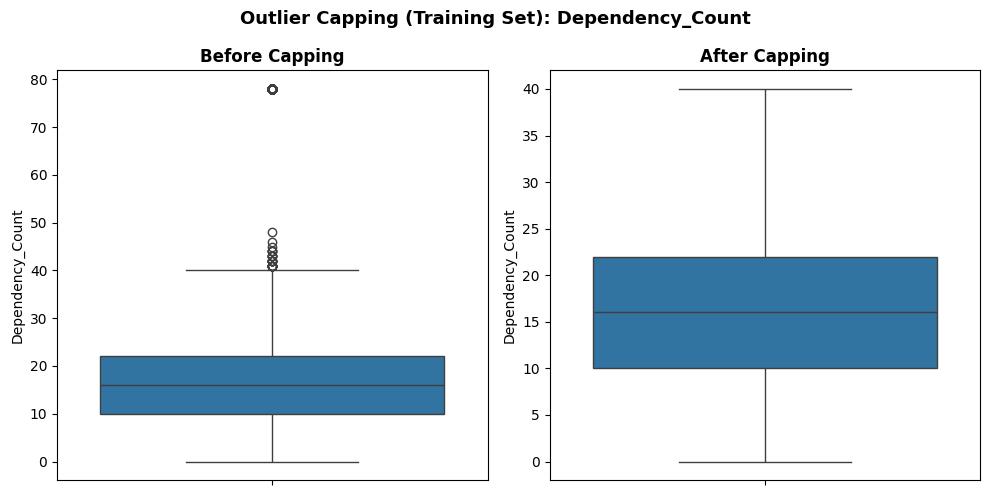

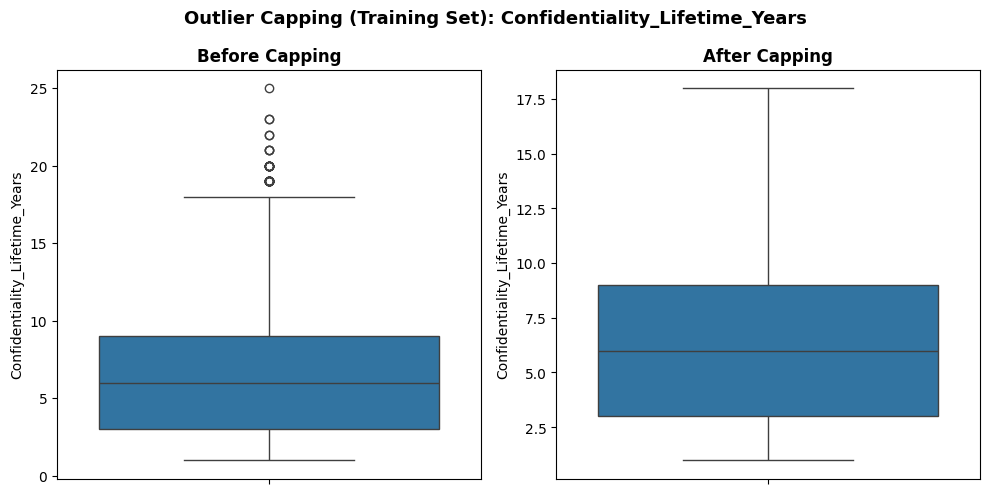

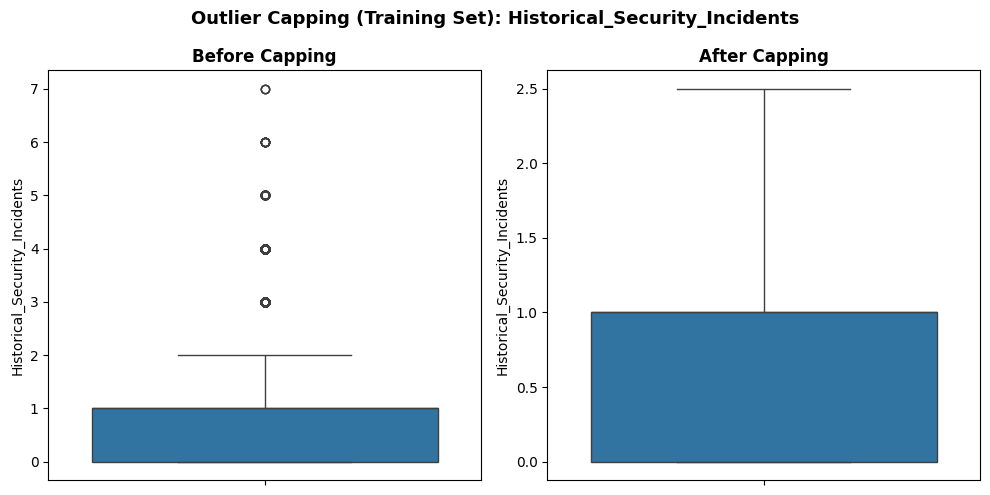

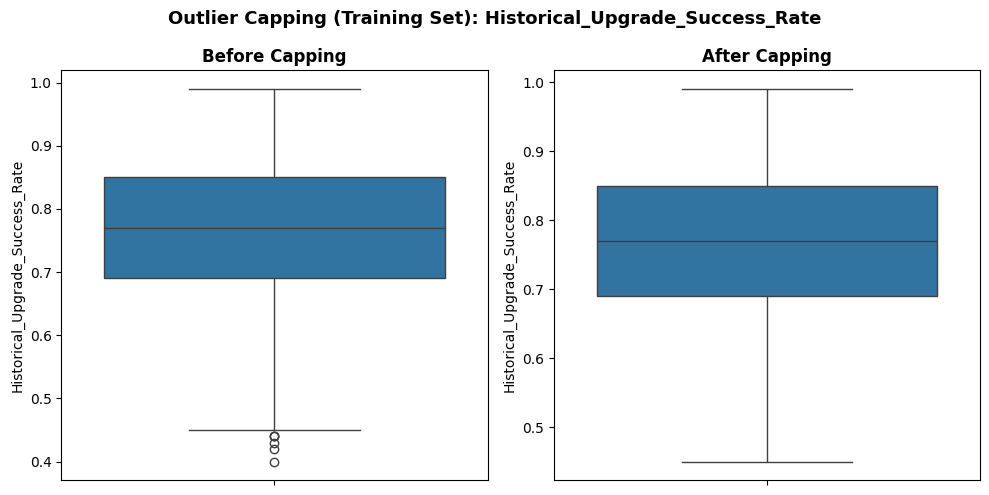

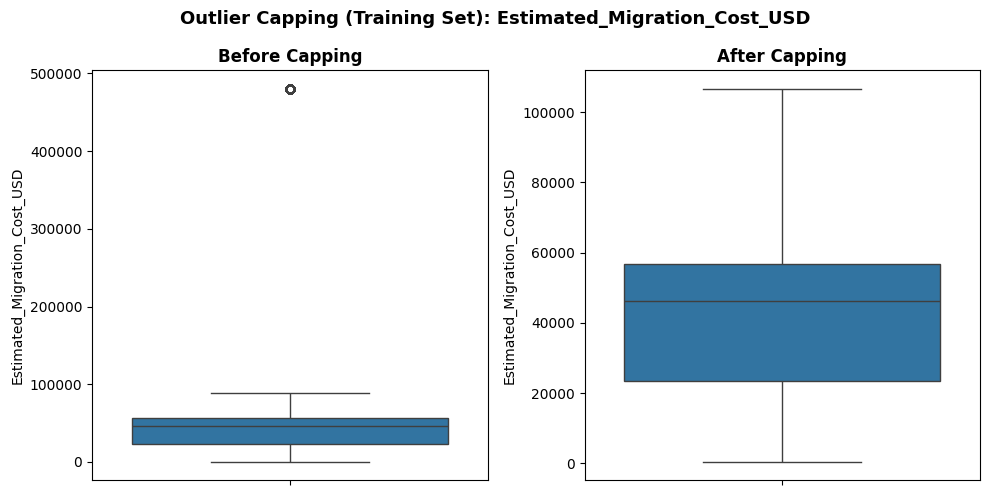

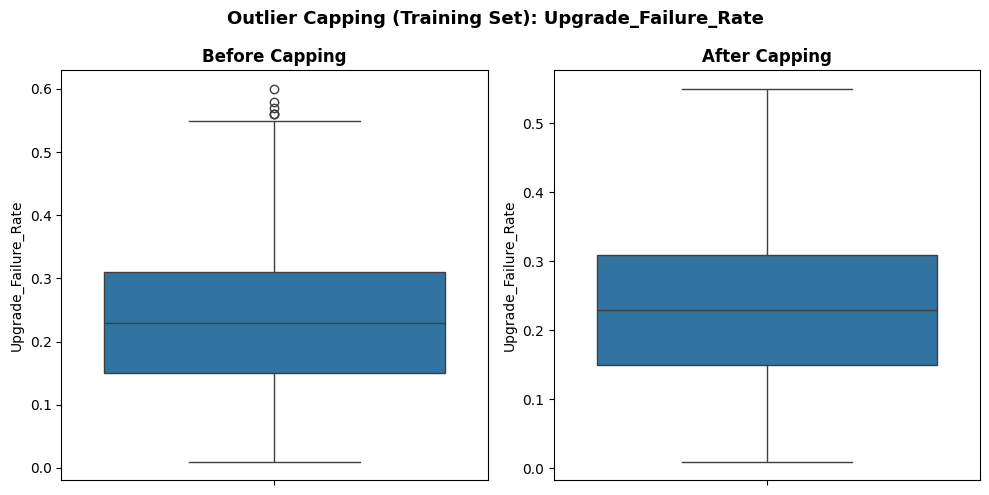

In [15]:
print("\n" + "=" * 60)
print("BOX PLOTS - BEFORE vs AFTER OUTLIER CAPPING (TRAINING SET)")
print("=" * 60)

# Keep only numerical features available in both datasets
valid_features = [
    col for col in numerical_features
    if col in X_train_selected.columns
    and col in X_train_capped.columns
]

missing_features = [
    col for col in numerical_features
    if col not in X_train_selected.columns
    or col not in X_train_capped.columns
]

if missing_features:
    print("\nSkipped missing features:", missing_features)

features_with_outliers = []

for col in valid_features:
    Q1 = X_train_selected[col].quantile(0.25)
    Q3 = X_train_selected[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_outliers = (
        (X_train_selected[col] < lower) |
        (X_train_selected[col] > upper)
    ).sum()

    if n_outliers > 0:
        features_with_outliers.append(col)

print(
    f"\nFeatures with outliers in training data: "
    f"{len(features_with_outliers)}"
)

for col in features_with_outliers:
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    sns.boxplot(y=X_train_selected[col], ax=axes[0])
    axes[0].set_title("Before Capping", fontweight="bold")

    sns.boxplot(y=X_train_capped[col], ax=axes[1])
    axes[1].set_title("After Capping", fontweight="bold")

    plt.suptitle(
        f"Outlier Capping (Training Set): {col}",
        fontsize=13,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

## K. Preprocessing Pipepline

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Use the selected features for the risk prediction model
selected_numerical_features = [
    col for col in risk_selected_features
    if col in numerical_features
]

selected_categorical_features = [
    col for col in risk_selected_features
    if col in categorical_features
]

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, selected_numerical_features),
    ("cat", categorical_pipeline, selected_categorical_features)
])

print("Numerical features:", len(selected_numerical_features))
print("Categorical features:", len(selected_categorical_features))
print("Total selected features:", len(risk_selected_features))

Numerical features: 8
Categorical features: 12
Total selected features: 20


In [17]:
print("Fitting preprocessor on TRAINING data...")

# Fit only on training data
preprocessor.fit(X_train_capped)

# Transform all three datasets using the same fitted preprocessor
X_train_processed = preprocessor.transform(X_train_capped)
X_val_processed = preprocessor.transform(X_val_capped)
X_test_processed = preprocessor.transform(X_test_capped)

print("\nProcessed shapes:")
print(f"  Training   : {X_train_processed.shape}")
print(f"  Validation : {X_val_processed.shape}")
print(f"  Test       : {X_test_processed.shape}")

# Validation checks
assert X_train_processed.shape[0] == len(Y_train)
assert X_val_processed.shape[0] == len(Y_val)
assert X_test_processed.shape[0] == len(Y_test)

assert X_train_processed.shape[1] == X_val_processed.shape[1]
assert X_train_processed.shape[1] == X_test_processed.shape[1]

print("\nAll preprocessing checks passed.")

Fitting preprocessor on TRAINING data...

Processed shapes:
  Training   : (14000, 82)
  Validation : (3000, 82)
  Test       : (3000, 82)

All preprocessing checks passed.


## Know datatypes of targets

In [18]:
for col in target_columns:

    print("\n" + "=" * 70)
    print(f"TARGET: {col}")
    print("=" * 70)

    if df_clean[col].dtype == "object":
        print(df_clean[col].value_counts())
    else:
        print(df_clean[col].describe())


TARGET: Quantum_Risk_Score
count    20000.00000
mean        62.53943
std         19.15661
min          2.40000
25%         48.60000
50%         62.20000
75%         77.00000
max        100.00000
Name: Quantum_Risk_Score, dtype: float64

TARGET: Recommended_PQC_Algorithm
Recommended_PQC_Algorithm
ML-KEM       10737
Hybrid        4850
No Change     3287
ML-DSA        1126
Name: count, dtype: int64

TARGET: Migration_Priority
Migration_Priority
High         7233
Medium       6694
Immediate    4694
Low          1379
Name: count, dtype: int64

TARGET: Estimated_Migration_Duration_Days
count    20000.000000
mean        20.829020
std          8.681558
min          1.000000
25%         14.300000
50%         22.800000
75%         27.400000
max         43.100000
Name: Estimated_Migration_Duration_Days, dtype: float64


### L. Prediction of Quantum_Risk_Score

## 1. Training and validation using multiple models

In [19]:

# ============================================================
# BASELINE REGRESSION MODEL COMPARISON
# Target: Quantum_Risk_Score
# Evaluation: Training and Validation Sets
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("\n" + "=" * 60)
print("BASELINE REGRESSION MODEL COMPARISON")
print("=" * 60)

# 1. Define models
reg_models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(
        alpha=1.0
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

# 2. Train and evaluate on validation data
reg_results = []
trained_reg_models = {}

for name, model in reg_models.items():

    print(f"\nTraining: {name}")

    model.fit(X_train_processed, y_train)

    val_pred = model.predict(X_val_processed)

    mae = mean_absolute_error(y_val, val_pred)
    rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    r2 = r2_score(y_val, val_pred)

    reg_results.append({
        "Model": name,
        "Val_MAE": mae,
        "Val_RMSE": rmse,
        "Val_R2": r2
    })

    trained_reg_models[name] = model

# 3. Compare models
reg_results_df = (
    pd.DataFrame(reg_results)
    .sort_values("Val_R2", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 60)
print("VALIDATION RESULTS")
print("=" * 60)

display(reg_results_df)

# 4. Best model
best_regression_name = reg_results_df.iloc[0]["Model"]
best_regression_model = trained_reg_models[best_regression_name]

print("\n" + "-" * 60)
print(f"Best Model: {best_regression_name}")
print(f"Validation R²: {reg_results_df.iloc[0]['Val_R2']:.4f}")
print(f"Validation MAE: {reg_results_df.iloc[0]['Val_MAE']:.4f}")
print(f"Validation RMSE: {reg_results_df.iloc[0]['Val_RMSE']:.4f}")
print("-" * 60)



BASELINE REGRESSION MODEL COMPARISON

Training: Linear Regression

Training: Ridge Regression

Training: Random Forest

Training: Gradient Boosting

VALIDATION RESULTS


,Model,Val_MAE,Val_RMSE,Val_R2
0,Ridge Regression,2.783727,3.501091,0.966620
1,Linear Regression,2.784075,3.501720,0.966608
2,Gradient Boosting,2.851183,3.593387,0.964837
3,Random Forest,2.907899,3.669713,0.963328



------------------------------------------------------------
Best Model: Ridge Regression
Validation R²: 0.9666
Validation MAE: 2.7837
Validation RMSE: 3.5011
------------------------------------------------------------


### 2. Tune the best model (validation)

In [20]:
# ============================================================
# STEP 9: TUNE RIDGE REGRESSION
# ============================================================

print("\n" + "=" * 60)
print("TUNING RIDGE REGRESSION")
print("=" * 60)

import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Define alpha values to test
# ------------------------------------------------------------

alphas = [0.001, 0.01, 0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0, 1000.0]


# ------------------------------------------------------------
# 2. Train Ridge with different alpha values
# ------------------------------------------------------------

results = []

for alpha in alphas:

    model = Ridge(alpha=alpha, random_state=42)

    model.fit(X_train_processed, y_train)

    val_pred = model.predict(X_val_processed)

    mae = mean_absolute_error(y_val, val_pred)
    rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    r2 = r2_score(y_val, val_pred)

    results.append({
        "Alpha": alpha,
        "Val_MAE": mae,
        "Val_RMSE": rmse,
        "Val_R2": r2
    })


# ------------------------------------------------------------
# 3. Display results
# ------------------------------------------------------------

tune_df = pd.DataFrame(results)
tune_df = tune_df.sort_values("Val_R2", ascending=False).reset_index(drop=True)

print("\nRidge Tuning Results:")
display(tune_df)


# ------------------------------------------------------------
# 4. Select best alpha
# ------------------------------------------------------------

best_alpha = tune_df.loc[tune_df["Val_R2"].idxmax(), "Alpha"]

print("\n" + "-" * 60)
print(f"Best Alpha : {best_alpha}")
print("-" * 60)


TUNING RIDGE REGRESSION

Ridge Tuning Results:


,Alpha,Val_MAE,Val_RMSE,Val_R2
0,10.000,2.781318,3.498673,0.966667
1,5.000,2.782539,3.499646,0.966648
2,1.000,2.783727,3.501091,0.966620
3,0.100,2.784223,3.501524,0.966612
4,0.001,2.784285,3.501651,0.966610
5,0.010,2.784295,3.501697,0.966609
6,50.000,2.804211,3.528255,0.966100
7,100.000,2.868701,3.607951,0.964552
8,500.000,3.528363,4.490443,0.945090
9,1000.000,4.272901,5.445688,0.919243



------------------------------------------------------------
Best Alpha : 10.0
------------------------------------------------------------


### 3. Evaluate the model

In [21]:

# ============================================================
# STEP 10: FINAL RIDGE MODEL EVALUATION
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# 1. Train final model using selected alpha
final_model = Ridge(alpha=best_alpha)

final_model.fit(X_train_processed, y_train)

# 2. Generate predictions
train_pred = np.clip(
    final_model.predict(X_train_processed), 0, 100
)
val_pred = np.clip(
    final_model.predict(X_val_processed), 0, 100
)
test_pred = np.clip(
    final_model.predict(X_test_processed), 0, 100
)

# 3. Calculate evaluation metrics
evaluation_results = []

for dataset_name, actual, predicted in [
    ("Training", y_train, train_pred),
    ("Validation", y_val, val_pred),
    ("Test", y_test, test_pred)
]:
    evaluation_results.append({
        "Dataset": dataset_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

evaluation_df = pd.DataFrame(evaluation_results)

# 4. Display results
print("=" * 65)
print("FINAL RIDGE REGRESSION EVALUATION")
print(f"Selected Alpha: {best_alpha}")
print("=" * 65)

display(evaluation_df)

# 5. Store final test metrics
test_mae = evaluation_df.loc[
    evaluation_df["Dataset"] == "Test", "MAE"
].iloc[0]

test_rmse = evaluation_df.loc[
    evaluation_df["Dataset"] == "Test", "RMSE"
].iloc[0]

test_r2 = evaluation_df.loc[
    evaluation_df["Dataset"] == "Test", "R2"
].iloc[0]

print("\nFinal Test Performance:")
print(f"MAE  : {test_mae:.4f}")
print(f"RMSE : {test_rmse:.4f}")
print(f"R²   : {test_r2:.4f}")


FINAL RIDGE REGRESSION EVALUATION
Selected Alpha: 10.0


,Dataset,MAE,RMSE,R2
0,Training,2.747026,3.462937,0.967320
1,Validation,2.725929,3.450050,0.967587
2,Test,2.645572,3.369462,0.969036



Final Test Performance:
MAE  : 2.6456
RMSE : 3.3695
R²   : 0.9690


### 4. Cross validation


5-FOLD CROSS-VALIDATION: RIDGE REGRESSION
Fold 1: R² = 0.9668
Fold 2: R² = 0.9643
Fold 3: R² = 0.9662
Fold 4: R² = 0.9678
Fold 5: R² = 0.9660

------------------------------------------------------------
Mean CV R²: 0.9662
Std Dev R²: 0.0011
Range: [0.9643, 0.9678]
------------------------------------------------------------


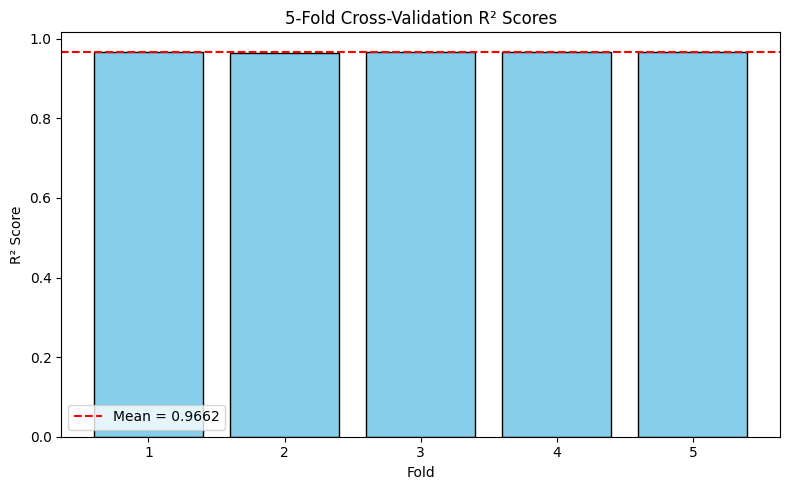

In [22]:

# ============================================================
# 5-FOLD CROSS-VALIDATION
# Fold-wise preprocessing for Ridge Regression
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

print("\n" + "=" * 60)
print("5-FOLD CROSS-VALIDATION: RIDGE REGRESSION")
print("=" * 60)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = []

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_train_capped), start=1
):

    X_fold_train = X_train_capped.iloc[train_idx]
    X_fold_val = X_train_capped.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Fit a fresh preprocessor within this fold
    fold_preprocessor = clone(preprocessor)

    X_fold_train_processed = fold_preprocessor.fit_transform(
        X_fold_train
    )

    X_fold_val_processed = fold_preprocessor.transform(
        X_fold_val
    )

    # Train Ridge using the selected alpha
    fold_model = Ridge(alpha=best_alpha)

    fold_model.fit(
        X_fold_train_processed,
        y_fold_train
    )

    fold_pred = fold_model.predict(X_fold_val_processed)

    fold_r2 = r2_score(y_fold_val, fold_pred)
    cv_scores.append(fold_r2)

    print(f"Fold {fold}: R² = {fold_r2:.4f}")

cv_scores = np.array(cv_scores)

print("\n" + "-" * 60)
print(f"Mean CV R²: {cv_scores.mean():.4f}")
print(f"Std Dev R²: {cv_scores.std():.4f}")
print(
    f"Range: [{cv_scores.min():.4f}, "
    f"{cv_scores.max():.4f}]"
)
print("-" * 60)

# Visualization
plt.figure(figsize=(8, 5))

plt.bar(
    range(1, 6),
    cv_scores,
    color="skyblue",
    edgecolor="black"
)

plt.axhline(
    cv_scores.mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {cv_scores.mean():.4f}"
)

plt.xlabel("Fold")
plt.ylabel("R² Score")
plt.title("5-Fold Cross-Validation R² Scores")
plt.xticks(range(1, 6))
plt.legend()
plt.tight_layout()
plt.show()


### 5. Visualizing


ACTUAL VS PREDICTED


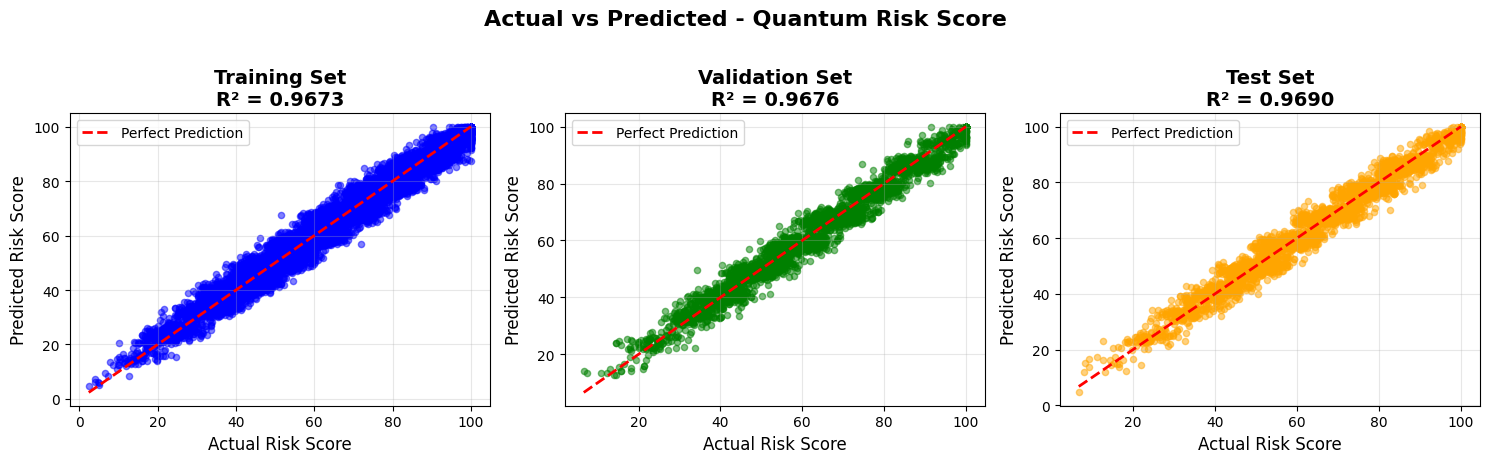


Prediction Statistics:
--------------------------------------------------
Training   - MAE: 2.7470, RMSE: 3.4629, R²: 0.9673
Validation - MAE: 2.7259, RMSE: 3.4500, R²: 0.9676
Test       - MAE: 2.6456, RMSE: 3.3695, R²: 0.9690


In [23]:
# ============================================================
# ACTUAL VS PREDICTED - Quantum_Risk_Score
# ============================================================

print("\n" + "="*60)
print("ACTUAL VS PREDICTED")
print("="*60)

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Get predictions
train_pred = np.clip(
    final_model.predict(X_train_processed), 0, 100
)
val_pred = np.clip(
    final_model.predict(X_val_processed), 0, 100
)
test_pred = np.clip(
    final_model.predict(X_test_processed), 0, 100
)

# Create figure
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# ---- TRAINING ----
axes[0].scatter(y_train, train_pred, alpha=0.5, color='blue', s=20)
axes[0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Risk Score', fontsize=12)
axes[0].set_ylabel('Predicted Risk Score', fontsize=12)
axes[0].set_title(f'Training Set\nR² = {r2_score(y_train, train_pred):.4f}', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ---- VALIDATION ----
axes[1].scatter(y_val, val_pred, alpha=0.5, color='green', s=20)
axes[1].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2, label='Perfect Prediction')
axes[1].set_xlabel('Actual Risk Score', fontsize=12)
axes[1].set_ylabel('Predicted Risk Score', fontsize=12)
axes[1].set_title(f'Validation Set\nR² = {r2_score(y_val, val_pred):.4f}', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# ---- TEST ----
axes[2].scatter(y_test, test_pred, alpha=0.5, color='orange', s=20)
axes[2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
axes[2].set_xlabel('Actual Risk Score', fontsize=12)
axes[2].set_ylabel('Predicted Risk Score', fontsize=12)
axes[2].set_title(f'Test Set\nR² = {r2_score(y_test, test_pred):.4f}', fontsize=14, fontweight='bold')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('Actual vs Predicted - Quantum Risk Score', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("real vs predicted.png", dpi=300, bbox_inches="tight")
plt.show()

# ---- SUMMARY STATISTICS ----
print("\nPrediction Statistics:")
print("-" * 50)
print(f"Training   - MAE: {mean_absolute_error(y_train, train_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_train, train_pred)):.4f}, R²: {r2_score(y_train, train_pred):.4f}")
print(f"Validation - MAE: {mean_absolute_error(y_val, val_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_val, val_pred)):.4f}, R²: {r2_score(y_val, val_pred):.4f}")
print(f"Test       - MAE: {mean_absolute_error(y_test, test_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, test_pred)):.4f}, R²: {r2_score(y_test, test_pred):.4f}")

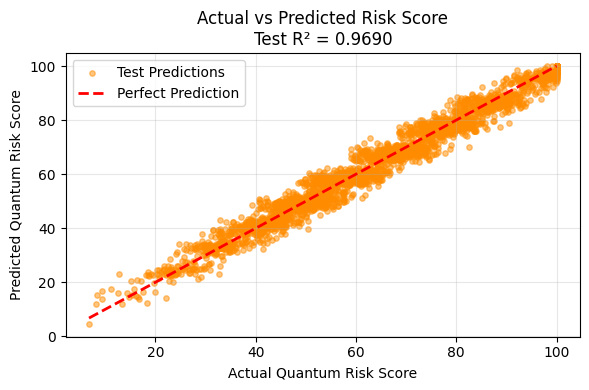

In [24]:
# ============================================================
# ACTUAL VS PREDICTED - TEST SET ONLY
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

plt.figure(figsize=(6, 4))

plt.scatter(
    y_test,
    test_pred,
    alpha=0.5,
    color="darkorange",
    s=15,
    label="Test Predictions"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Quantum Risk Score")
plt.ylabel("Predicted Quantum Risk Score")

plt.title(
    f"Actual vs Predicted Risk Score\n"
    f"Test R² = {r2_score(y_test, test_pred):.4f}"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "risk_score_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5. Download model

## PQC algorithm

##1. Create Features

In [25]:

# ============================================================
# PQC MIGRATION FEATURES
# Target: Recommended_PQC_Algorithm
# ============================================================

# Use all valid engineered predictors
excluded_features = [
    "Strong_Key",
    "Business_Impact"
]

pqc_features = [
    col for col in feature_columns
    if col not in excluded_features
]

# Ensure no target leakage through target columns
assert not any(col in pqc_features for col in target_columns)

# Ensure invalid/redundant features are excluded
assert "Strong_Key" not in pqc_features
assert "Business_Impact" not in pqc_features

print("Number of PQC input features:", len(pqc_features))
print("\nPQC input features:")
for i, col in enumerate(pqc_features, start=1):
    print(f"{i}. {col}")


Number of PQC input features: 32

PQC input features:
1. Current_Key_Size
2. Certificate_Age_Days
3. Certificate_Expiry_Days
4. Dependency_Count
5. Daily_Connections
6. Daily_Transactions
7. Confidentiality_Lifetime_Years
8. Historical_Security_Incidents
9. Historical_Upgrade_Success_Rate
10. Estimated_Downtime_Hours
11. Estimated_Migration_Cost_USD
12. Business_Impact_Score
13. Incident_Rate
14. Upgrade_Failure_Rate
15. Cost_Per_Hour
16. Asset_Type
17. Business_Unit
18. Environment
19. Cloud_Provider
20. Region
21. Operating_System
22. Current_Cryptographic_Algorithm
23. Crypto_Purpose
24. Internet_Facing
25. Criticality
26. Data_Sensitivity
27. Compliance
28. Blast_Radius
29. Legacy_System
30. Performance_Constraint
31. Migration_Complexity
32. Team_Readiness


In [26]:

# ============================================================
# PQC FEATURES WITH LEAKAGE-CONTROLLED OOF QUANTUM RISK
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.feature_selection import f_classif
from sklearn.compose import ColumnTransformer

# ------------------------------------------------------------
# 1. ORIGINAL FEATURES AND TARGETS
# ------------------------------------------------------------

X_pqc_train = X_train[pqc_features].copy()
X_pqc_val   = X_val[pqc_features].copy()
X_pqc_test  = X_test[pqc_features].copy()

y_pqc_train = Y_train.loc[
    X_pqc_train.index, "Recommended_PQC_Algorithm"
]
y_pqc_val = Y_val.loc[
    X_pqc_val.index, "Recommended_PQC_Algorithm"
]
y_pqc_test = Y_test.loc[
    X_pqc_test.index, "Recommended_PQC_Algorithm"
]

# Use the ORIGINAL, uncapped training predictors for fold-local
# feature selection and outlier-threshold estimation.
X_risk_raw_train = X_train[risk_all_features].copy()

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_risk_predictions = np.zeros(len(X_risk_raw_train), dtype=float)

# ------------------------------------------------------------
# 2. FIVE-FOLD OOF RISK GENERATION
# ------------------------------------------------------------

for fold, (train_idx, valid_idx) in enumerate(
    kf.split(X_risk_raw_train), start=1
):
    print(f"\nProcessing risk OOF fold {fold}/5")

    X_fold_raw_train = X_risk_raw_train.iloc[train_idx].copy()
    X_fold_raw_valid = X_risk_raw_train.iloc[valid_idx].copy()

    y_fold_train = y_train.loc[X_fold_raw_train.index]

    # --------------------------------------------------------
    # A. FIT FEATURE-SELECTION PREPROCESSOR ON FOLD TRAIN ONLY
    # --------------------------------------------------------

    fold_selection_preprocessor = clone(risk_preprocessor)

    X_fold_encoded = fold_selection_preprocessor.fit_transform(
        X_fold_raw_train
    )

    if hasattr(X_fold_encoded, "toarray"):
        X_fold_encoded = X_fold_encoded.toarray()

    # Fit target discretization only on fold-training targets.
    fold_discretizer = KBinsDiscretizer(
        n_bins=5,
        encode="ordinal",
        strategy="quantile"
    )

    y_fold_binned = fold_discretizer.fit_transform(
        y_fold_train.to_numpy().reshape(-1, 1)
    ).ravel()

    fold_f_scores, fold_p_values = f_classif(
        X_fold_encoded,
        y_fold_binned
    )

    fold_encoded_names = (
        fold_selection_preprocessor.get_feature_names_out()
    )

    fold_encoded_results = pd.DataFrame({
        "encoded_feature": fold_encoded_names,
        "f_score": np.nan_to_num(
            fold_f_scores, nan=-np.inf
        ),
        "p_value": np.nan_to_num(
            fold_p_values, nan=1.0
        )
    })

    def map_fold_feature(encoded_name):
        name = encoded_name.split("__", 1)[-1]

        for col in sorted(risk_all_features, key=len, reverse=True):
            if name == col or name.startswith(col + "_"):
                return col

        return name

    fold_encoded_results["original_feature"] = (
        fold_encoded_results["encoded_feature"].apply(
            map_fold_feature
        )
    )

    fold_ranked = (
        fold_encoded_results
        .groupby("original_feature")
        .agg(
            f_score=("f_score", "max"),
            p_value=("p_value", "min")
        )
        .reset_index()
        .sort_values("f_score", ascending=False)
    )

    fold_selected_features = (
        fold_ranked["original_feature"].head(20).tolist()
    )

    # Keep numerical/categorical feature types consistent.
    fold_num_features = [
        c for c in fold_selected_features
        if c in numerical_features
    ]
    fold_cat_features = [
        c for c in fold_selected_features
        if c in categorical_features
    ]

    # --------------------------------------------------------
    # B. FIT IQR THRESHOLDS ON FOLD TRAIN ONLY
    # --------------------------------------------------------

    fold_outlier_features = [
        c for c in fold_num_features
        if c not in ["Current_Key_Size", "Business_Impact_Score"]
    ]

    fold_thresholds = get_outlier_thresholds(
        X_fold_raw_train[fold_selected_features],
        fold_outlier_features
    )

    X_fold_train = cap_outliers(
        X_fold_raw_train[fold_selected_features],
        fold_thresholds,
        fold_outlier_features
    )

    X_fold_valid = cap_outliers(
        X_fold_raw_valid[fold_selected_features],
        fold_thresholds,
        fold_outlier_features
    )

    # --------------------------------------------------------
    # C. FIT IMPUTATION / SCALING / ENCODING ON FOLD TRAIN ONLY
    # --------------------------------------------------------

    fold_preprocessor = ColumnTransformer(
        transformers=[
            ("num", clone(numeric_pipeline), fold_num_features),
            ("cat", clone(categorical_pipeline), fold_cat_features)
        ],
        remainder="drop"
    )

    X_fold_train_processed = fold_preprocessor.fit_transform(
        X_fold_train
    )
    X_fold_valid_processed = fold_preprocessor.transform(
        X_fold_valid
    )

    # --------------------------------------------------------
    # D. FIT FOLD MODEL AND PREDICT HELD-OUT FOLD
    # --------------------------------------------------------

    fold_model = Ridge(alpha=best_alpha)

    fold_model.fit(
        X_fold_train_processed,
        y_fold_train
    )

    oof_risk_predictions[valid_idx] = fold_model.predict(
        X_fold_valid_processed
    )

    print(
        f"Fold {fold} completed | "
        f"selected features: {len(fold_selected_features)}"
    )

# ------------------------------------------------------------
# 3. VALIDATION AND TEST RISK PREDICTIONS
# Use the final model/preprocessor fitted on the full
# training partition, not the fold-specific models.
# ------------------------------------------------------------

X_risk_val = X_val_capped.copy()
X_risk_test = X_test_capped.copy()

X_val_risk_processed = preprocessor.transform(X_risk_val)
X_test_risk_processed = preprocessor.transform(X_risk_test)

val_risk_predictions = final_model.predict(
    X_val_risk_processed
)
test_risk_predictions = final_model.predict(
    X_test_risk_processed
)
# Keep all predicted risk scores within the defined 0–100 scale
oof_risk_predictions = np.clip(oof_risk_predictions, 0, 100)
val_risk_predictions = np.clip(val_risk_predictions, 0, 100)
test_risk_predictions = np.clip(test_risk_predictions, 0, 100)

# ------------------------------------------------------------
# 4. ADD RISK PREDICTIONS TO PQC FEATURES
# ------------------------------------------------------------

X_pqc_train["Quantum_Risk_Score"] = oof_risk_predictions
X_pqc_val["Quantum_Risk_Score"] = val_risk_predictions
X_pqc_test["Quantum_Risk_Score"] = test_risk_predictions

# ------------------------------------------------------------
# 5. ALIGNMENT CHECKS
# ------------------------------------------------------------

assert len(oof_risk_predictions) == len(X_pqc_train)
assert X_pqc_train.index.equals(y_pqc_train.index)
assert X_pqc_val.index.equals(y_pqc_val.index)
assert X_pqc_test.index.equals(y_pqc_test.index)

assert np.isfinite(oof_risk_predictions).all()
assert np.isfinite(val_risk_predictions).all()
assert np.isfinite(test_risk_predictions).all()

print("\nRisk OOF generation completed.")
print("Training:", X_pqc_train.shape)
print("Validation:", X_pqc_val.shape)
print("Test:", X_pqc_test.shape)
print("\nOOF risk prediction summary:")
print(pd.Series(oof_risk_predictions).describe())



Processing risk OOF fold 1/5
Fold 1 completed | selected features: 20

Processing risk OOF fold 2/5
Fold 2 completed | selected features: 20

Processing risk OOF fold 3/5
Fold 3 completed | selected features: 20

Processing risk OOF fold 4/5
Fold 4 completed | selected features: 20

Processing risk OOF fold 5/5
Fold 5 completed | selected features: 20

Risk OOF generation completed.
Training: (14000, 33)
Validation: (3000, 33)
Test: (3000, 33)

OOF risk prediction summary:
count    14000.000000
mean        62.548221
std         18.665170
min          4.846748
25%         49.081211
50%         61.295158
75%         77.056644
max        100.000000
dtype: float64


## Numerical vs categorical features

In [27]:

# ============================================================
# PQC FEATURE TYPE IDENTIFICATION
# ============================================================

pqc_numerical_features = X_pqc_train.select_dtypes(
    include=["number"]
).columns.tolist()

pqc_categorical_features = X_pqc_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(pqc_numerical_features))
print("Categorical features:", len(pqc_categorical_features))
print("Total features:",
      len(pqc_numerical_features) + len(pqc_categorical_features))

# Verify feature consistency across all datasets
assert X_pqc_train.columns.equals(X_pqc_val.columns)
assert X_pqc_train.columns.equals(X_pqc_test.columns)

assert len(pqc_numerical_features) + len(pqc_categorical_features) == X_pqc_train.shape[1]

print("\nFeature type verification passed.")
print("\nNumerical:", pqc_numerical_features)
print("\nCategorical:", pqc_categorical_features)


Numerical features: 16
Categorical features: 17
Total features: 33

Feature type verification passed.

Numerical: ['Current_Key_Size', 'Certificate_Age_Days', 'Certificate_Expiry_Days', 'Dependency_Count', 'Daily_Connections', 'Daily_Transactions', 'Confidentiality_Lifetime_Years', 'Historical_Security_Incidents', 'Historical_Upgrade_Success_Rate', 'Estimated_Downtime_Hours', 'Estimated_Migration_Cost_USD', 'Business_Impact_Score', 'Incident_Rate', 'Upgrade_Failure_Rate', 'Cost_Per_Hour', 'Quantum_Risk_Score']

Categorical: ['Asset_Type', 'Business_Unit', 'Environment', 'Cloud_Provider', 'Region', 'Operating_System', 'Current_Cryptographic_Algorithm', 'Crypto_Purpose', 'Internet_Facing', 'Criticality', 'Data_Sensitivity', 'Compliance', 'Blast_Radius', 'Legacy_System', 'Performance_Constraint', 'Migration_Complexity', 'Team_Readiness']


##2. Train/validation/Test

In [28]:

# ============================================================
# PQC TRAIN / VALIDATION / TEST DATASETS
# Use OOF risk predictions from the previous cell
# ============================================================

X_train_pqc = X_pqc_train.copy()
X_val_pqc = X_pqc_val.copy()
X_test_pqc = X_pqc_test.copy()

y_train_pqc = y_pqc_train.copy()
y_val_pqc = y_pqc_val.copy()
y_test_pqc = y_pqc_test.copy()

print("Training:", X_train_pqc.shape, y_train_pqc.shape)
print("Validation:", X_val_pqc.shape, y_val_pqc.shape)
print("Test:", X_test_pqc.shape, y_test_pqc.shape)

# Verify alignment
assert X_train_pqc.index.equals(y_train_pqc.index)
assert X_val_pqc.index.equals(y_val_pqc.index)
assert X_test_pqc.index.equals(y_test_pqc.index)

# Verify there is no overlap
assert len(set(X_train_pqc.index) & set(X_val_pqc.index)) == 0
assert len(set(X_train_pqc.index) & set(X_test_pqc.index)) == 0
assert len(set(X_val_pqc.index) & set(X_test_pqc.index)) == 0

print("\nAll split and alignment checks passed.")


Training: (14000, 33) (14000,)
Validation: (3000, 33) (3000,)
Test: (3000, 33) (3000,)

All split and alignment checks passed.


##3. Preprocessing

In [29]:

# ============================================================
# PQC CLASSIFICATION PREPROCESSING
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_transformer_pqc = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_pqc = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combined preprocessing
preprocessor_pqc = ColumnTransformer([
    ("num", numeric_transformer_pqc, pqc_numerical_features),
    ("cat", categorical_transformer_pqc, pqc_categorical_features)
])

# Fit exclusively on training data
X_train_pqc_processed = preprocessor_pqc.fit_transform(
    X_train_pqc
)

# Transform validation and test using fitted preprocessor
X_val_pqc_processed = preprocessor_pqc.transform(
    X_val_pqc
)

X_test_pqc_processed = preprocessor_pqc.transform(
    X_test_pqc
)

# Verify dimensions
print("Train processed:", X_train_pqc_processed.shape)
print("Validation processed:", X_val_pqc_processed.shape)
print("Test processed:", X_test_pqc_processed.shape)

assert X_train_pqc_processed.shape[1] == X_val_pqc_processed.shape[1]
assert X_train_pqc_processed.shape[1] == X_test_pqc_processed.shape[1]

print("\nPQC preprocessing completed successfully.")


Train processed: (14000, 121)
Validation processed: (3000, 121)
Test processed: (3000, 121)

PQC preprocessing completed successfully.


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

models_pqc = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=42
    ),

    "SVM": SVC(
        kernel="rbf",
        C=2,
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
        n_jobs=-1
    )
}

pqc_results = []

for name, model in models_pqc.items():
    model.fit(X_train_pqc_processed, y_train_pqc)

    y_val_pred = model.predict(X_val_pqc_processed)

    accuracy = accuracy_score(y_val_pqc, y_val_pred)
    macro_f1 = f1_score(y_val_pqc, y_val_pred, average="macro")

    pqc_results.append({
        "Model": name,
        "Accuracy": round(accuracy, 4),
        "Macro F1": round(macro_f1, 4)
    })

pqc_results_df = pd.DataFrame(pqc_results).sort_values(
    by="Macro F1",
    ascending=False
)

display(pqc_results_df)

,Model,Accuracy,Macro F1
0,Logistic Regression,0.7103,0.7724
5,SVM,0.7080,0.7700
3,Gradient Boosting,0.7473,0.7251
2,Extra Trees,0.7503,0.7248
4,Hist Gradient Boosting,0.7427,0.7091
6,KNN,0.7130,0.6961
1,Random Forest,0.7533,0.6960


In [31]:
# ============================================================
# PQC RECOMMENDATION - LOGISTIC REGRESSION HYPERPARAMETER TUNING
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# ------------------------------------------------------------
# 1. BUILD COMPLETE PIPELINE
# ------------------------------------------------------------

lr_pipeline_pqc = Pipeline([
    ("preprocessor", preprocessor_pqc),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])

# ------------------------------------------------------------
# 2. HYPERPARAMETER GRID
# ------------------------------------------------------------

param_grid_pqc = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs", "liblinear"]
}

# ------------------------------------------------------------
# 3. STRATIFIED CROSS-VALIDATION
# ------------------------------------------------------------

cv_pqc = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 4. GRID SEARCH
# ------------------------------------------------------------

grid_pqc = GridSearchCV(
    estimator=lr_pipeline_pqc,
    param_grid=param_grid_pqc,
    cv=cv_pqc,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_pqc.fit(
    X_train_pqc,
    y_train_pqc
)

# ------------------------------------------------------------
# 5. RESULTS
# ------------------------------------------------------------

print("\nBest Parameters:")
print(grid_pqc.best_params_)

print("\nBest CV Macro F1:")
print(round(grid_pqc.best_score_, 4))

best_pqc_model = grid_pqc.best_estimator_

print("\nBest PQC model fitted successfully.")

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best Parameters:
{'classifier__C': 0.01, 'classifier__solver': 'lbfgs'}

Best CV Macro F1:
0.7742

Best PQC model fitted successfully.


In [32]:
best_pqc_model = grid_pqc.best_estimator_

# Validation
y_val_pred_pqc = best_pqc_model.predict(X_val_pqc)

print("Validation Accuracy:",
      round(accuracy_score(y_val_pqc, y_val_pred_pqc), 4))

print("Validation Macro F1:",
      round(f1_score(y_val_pqc, y_val_pred_pqc, average="macro"), 4))

# Test
y_test_pred_pqc = best_pqc_model.predict(X_test_pqc)

print("\nTest Accuracy:",
      round(accuracy_score(y_test_pqc, y_test_pred_pqc), 4))

print("Test Macro F1:",
      round(f1_score(y_test_pqc, y_test_pred_pqc, average="macro"), 4))

Validation Accuracy: 0.7087
Validation Macro F1: 0.7711

Test Accuracy: 0.715
Test Macro F1: 0.7786


In [33]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_test_pqc,
    y_test_pred_pqc
))

              precision    recall  f1-score   support

      Hybrid       0.46      0.68      0.55       754
      ML-DSA       0.76      1.00      0.86       178
      ML-KEM       0.84      0.61      0.70      1566
   No Change       1.00      1.00      1.00       502

    accuracy                           0.71      3000
   macro avg       0.76      0.82      0.78      3000
weighted avg       0.76      0.71      0.72      3000



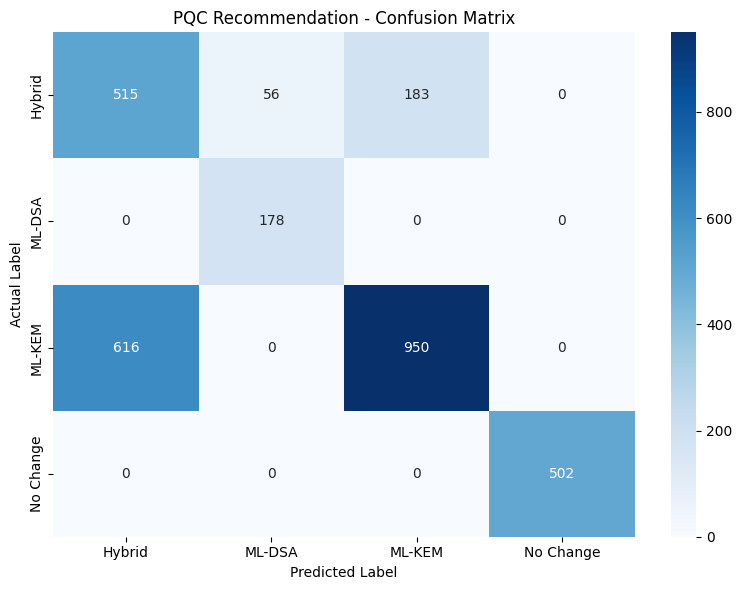

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = ["Hybrid", "ML-DSA", "ML-KEM", "No Change"]

cm = confusion_matrix(
    y_test_pqc,
    y_test_pred_pqc,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("PQC Recommendation - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig("confusion matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Migration Priority

## 1. Input features

In [35]:

# ============================================================
# MIGRATION PRIORITY - NESTED OOF PQC PREDICTIONS
# ============================================================

from sklearn.model_selection import cross_val_predict, StratifiedKFold
import numpy as np

# ------------------------------------------------------------
# 1. OUTER CV: GENERATE LEAKAGE-CONTROLLED OOF PREDICTIONS
# ------------------------------------------------------------

outer_cv_pqc = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=2026
)

# grid_pqc contains the complete preprocessing + classifier
# pipeline and the inner GridSearchCV configuration.
#
# Each outer training fold independently performs its own
# inner hyperparameter search.
#
# n_jobs=1 avoids nested parallel-processing conflicts.
# The inner GridSearchCV retains its existing n_jobs=-1.

oof_pqc_predictions = cross_val_predict(
    estimator=grid_pqc,
    X=X_train_pqc,
    y=y_train_pqc,
    cv=outer_cv_pqc,
    method="predict",
    n_jobs=1
)

# ------------------------------------------------------------
# 2. VALIDATION AND TEST PREDICTIONS
# ------------------------------------------------------------

# best_pqc_model is fitted on the complete training partition
# using the previously selected hyperparameters.

val_pqc_predictions = best_pqc_model.predict(
    X_val_pqc
)

test_pqc_predictions = best_pqc_model.predict(
    X_test_pqc
)

# ------------------------------------------------------------
# 3. CONSTRUCT PRIORITY INPUT FEATURES
# ------------------------------------------------------------

X_priority_train = X_pqc_train.copy()
X_priority_val = X_pqc_val.copy()
X_priority_test = X_pqc_test.copy()

X_priority_train["Recommended_PQC_Algorithm"] = (
    oof_pqc_predictions
)

X_priority_val["Recommended_PQC_Algorithm"] = (
    val_pqc_predictions
)

X_priority_test["Recommended_PQC_Algorithm"] = (
    test_pqc_predictions
)

# ------------------------------------------------------------
# 4. PRESERVE ORIGINAL TARGETS
# ------------------------------------------------------------

y_priority_train = Y_train.loc[
    X_priority_train.index,
    "Migration_Priority"
]

y_priority_val = Y_val.loc[
    X_priority_val.index,
    "Migration_Priority"
]

y_priority_test = Y_test.loc[
    X_priority_test.index,
    "Migration_Priority"
]

# ------------------------------------------------------------
# 5. VALIDATION
# ------------------------------------------------------------

assert len(oof_pqc_predictions) == len(X_priority_train)

assert X_priority_train.index.equals(y_priority_train.index)
assert X_priority_val.index.equals(y_priority_val.index)
assert X_priority_test.index.equals(y_priority_test.index)

assert not pd.isna(oof_pqc_predictions).any()

assert set(X_priority_train.index).isdisjoint(
    X_priority_val.index
)

assert set(X_priority_train.index).isdisjoint(
    X_priority_test.index
)

print("Nested OOF PQC generation completed.")
print("Training:", X_priority_train.shape)
print("Validation:", X_priority_val.shape)
print("Test:", X_priority_test.shape)

print("\nOOF PQC prediction distribution:")
print(pd.Series(oof_pqc_predictions).value_counts())


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Nested OOF PQC generation completed.
Training: (14000, 34)
Validation: (3000, 34)
Test: (3000, 34)

OOF PQC prediction distribution:
ML-KEM       5383
Hybrid       5230
No Change    2299
ML-DSA       1088
Name: count, dtype: int64


##2.Preprocessing

In [36]:

# ============================================================
# MIGRATION PRIORITY - FEATURE TYPES
# ============================================================

# Identify feature types using training data only
priority_numerical_features = X_priority_train.select_dtypes(
    include=["number"]
).columns.tolist()

priority_categorical_features = X_priority_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Verify identical feature columns across all splits
assert X_priority_train.columns.equals(X_priority_val.columns)
assert X_priority_train.columns.equals(X_priority_test.columns)

# Verify every feature is included exactly once
assert (
    len(priority_numerical_features)
    + len(priority_categorical_features)
    == X_priority_train.shape[1]
)

print("Numerical features:", len(priority_numerical_features))
print("Categorical features:", len(priority_categorical_features))

print("\nNumerical:")
print(priority_numerical_features)

print("\nCategorical:")
print(priority_categorical_features)

print("\nMigration Priority feature types verified.")


Numerical features: 16
Categorical features: 18

Numerical:
['Current_Key_Size', 'Certificate_Age_Days', 'Certificate_Expiry_Days', 'Dependency_Count', 'Daily_Connections', 'Daily_Transactions', 'Confidentiality_Lifetime_Years', 'Historical_Security_Incidents', 'Historical_Upgrade_Success_Rate', 'Estimated_Downtime_Hours', 'Estimated_Migration_Cost_USD', 'Business_Impact_Score', 'Incident_Rate', 'Upgrade_Failure_Rate', 'Cost_Per_Hour', 'Quantum_Risk_Score']

Categorical:
['Asset_Type', 'Business_Unit', 'Environment', 'Cloud_Provider', 'Region', 'Operating_System', 'Current_Cryptographic_Algorithm', 'Crypto_Purpose', 'Internet_Facing', 'Criticality', 'Data_Sensitivity', 'Compliance', 'Blast_Radius', 'Legacy_System', 'Performance_Constraint', 'Migration_Complexity', 'Team_Readiness', 'Recommended_PQC_Algorithm']

Migration Priority feature types verified.


In [37]:

# ============================================================
# MIGRATION PRIORITY - USE EXISTING DATA SPLITS
# ============================================================

# Reuse the existing correctly aligned datasets.
# Do NOT perform another train_test_split.

X_train_priority = X_priority_train.copy()
X_val_priority = X_priority_val.copy()
X_test_priority = X_priority_test.copy()

y_train_priority = y_priority_train.copy()
y_val_priority = y_priority_val.copy()
y_test_priority = y_priority_test.copy()

# Verify dimensions
print("Train:", X_train_priority.shape, y_train_priority.shape)
print("Validation:", X_val_priority.shape, y_val_priority.shape)
print("Test:", X_test_priority.shape, y_test_priority.shape)

# Verify index alignment
assert X_train_priority.index.equals(y_train_priority.index)
assert X_val_priority.index.equals(y_val_priority.index)
assert X_test_priority.index.equals(y_test_priority.index)

# Verify no overlap
assert set(X_train_priority.index).isdisjoint(X_val_priority.index)
assert set(X_train_priority.index).isdisjoint(X_test_priority.index)
assert set(X_val_priority.index).isdisjoint(X_test_priority.index)

print("\nMigration Priority splits verified successfully.")


Train: (14000, 34) (14000,)
Validation: (3000, 34) (3000,)
Test: (3000, 34) (3000,)

Migration Priority splits verified successfully.


In [38]:

# ============================================================
# MIGRATION PRIORITY - PREPROCESSING
# ============================================================

# Numerical preprocessing
numeric_transformer_priority = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_priority = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combined preprocessing
preprocessor_priority = ColumnTransformer([
    ("num", numeric_transformer_priority, priority_numerical_features),
    ("cat", categorical_transformer_priority, priority_categorical_features)
])

# Fit only on training data
X_train_priority_processed = preprocessor_priority.fit_transform(
    X_train_priority
)

X_val_priority_processed = preprocessor_priority.transform(
    X_val_priority
)

X_test_priority_processed = preprocessor_priority.transform(
    X_test_priority
)

# Verify dimensions
print("Train:", X_train_priority_processed.shape)
print("Validation:", X_val_priority_processed.shape)
print("Test:", X_test_priority_processed.shape)

assert X_train_priority_processed.shape[1] == X_val_priority_processed.shape[1]
assert X_train_priority_processed.shape[1] == X_test_priority_processed.shape[1]

print("\nMigration Priority preprocessing completed.")


Train: (14000, 125)
Validation: (3000, 125)
Test: (3000, 125)

Migration Priority preprocessing completed.


In [39]:
# ============================================================
# MIGRATION PRIORITY - MODEL COMPARISON
# ============================================================

models_priority = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=42
    ),

    "SVM": SVC(
        kernel="rbf",
        C=2,
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
        n_jobs=-1
    )
}

priority_results = []

for name, model in models_priority.items():
    model.fit(
        X_train_priority_processed,
        y_train_priority
    )

    y_pred = model.predict(
        X_val_priority_processed
    )

    priority_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val_priority, y_pred),
        "Macro F1": f1_score(
            y_val_priority,
            y_pred,
            average="macro"
        )
    })

priority_results_df = pd.DataFrame(priority_results)

priority_results_df = priority_results_df.sort_values(
    by="Macro F1",
    ascending=False
)

display(priority_results_df)

,Model,Accuracy,Macro F1
4,Hist Gradient Boosting,0.770000,0.752664
3,Gradient Boosting,0.769667,0.752476
1,Random Forest,0.747667,0.731659
5,SVM,0.720000,0.707911
2,Extra Trees,0.719000,0.703829
0,Logistic Regression,0.698333,0.686099
6,KNN,0.664333,0.643398


In [40]:

# ============================================================
# MIGRATION PRIORITY - FAST HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Preprocessing + Hist Gradient Boosting pipeline
hgb_pipeline_priority = Pipeline([
    ("preprocessor", preprocessor_priority),
    ("model", HistGradientBoostingClassifier(
        random_state=42
    ))
])

# Hyperparameter search space
param_grid_priority = {
    "model__max_iter": [200, 300],
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [31, 63]
}

# Reproducible stratified cross-validation
cv_priority = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Grid search
grid_priority = GridSearchCV(
    hgb_pipeline_priority,
    param_grid_priority,
    cv=cv_priority,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True
)

grid_priority.fit(
    X_train_priority,
    y_train_priority
)

print("Best Parameters:")
print(grid_priority.best_params_)

print("\nBest CV Macro F1:")
print(round(grid_priority.best_score_, 4))


Best Parameters:
{'model__learning_rate': 0.05, 'model__max_iter': 200, 'model__max_leaf_nodes': 31}

Best CV Macro F1:
0.7468


In [41]:
# ============================================================
# MIGRATION PRIORITY - FINAL MODEL EVALUATION
# ============================================================

best_priority_model = grid_priority.best_estimator_

# Validation
y_val_pred_priority = best_priority_model.predict(X_val_priority)

print("Tuned Validation Accuracy:",
      round(accuracy_score(y_val_priority, y_val_pred_priority), 4))

print("Tuned Validation Macro F1:",
      round(f1_score(
          y_val_priority,
          y_val_pred_priority,
          average="macro"
      ), 4))

# Test
y_test_pred_priority = best_priority_model.predict(X_test_priority)

print("\nTuned Test Accuracy:",
      round(accuracy_score(y_test_priority, y_test_pred_priority), 4))

print("Tuned Test Macro F1:",
      round(f1_score(
          y_test_priority,
          y_test_pred_priority,
          average="macro"
      ), 4))

Tuned Validation Accuracy: 0.77
Tuned Validation Macro F1: 0.7527

Tuned Test Accuracy: 0.7923
Tuned Test Macro F1: 0.7786


In [42]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_priority,
    y_test_pred_priority
))

              precision    recall  f1-score   support

        High       0.76      0.76      0.76      1080
   Immediate       0.86      0.81      0.83       699
         Low       0.76      0.66      0.71       196
      Medium       0.79      0.84      0.81      1025

    accuracy                           0.79      3000
   macro avg       0.79      0.77      0.78      3000
weighted avg       0.79      0.79      0.79      3000



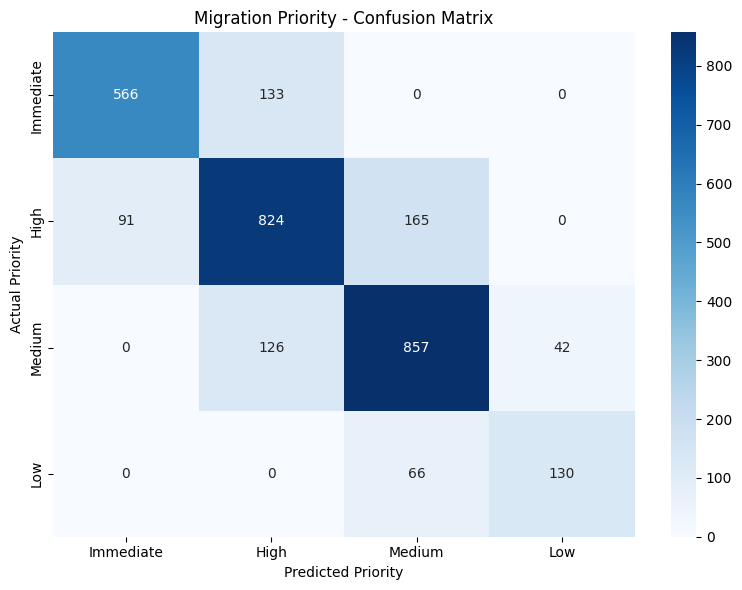

In [43]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

priority_labels = ["Immediate", "High", "Medium", "Low"]

cm_priority = confusion_matrix(
    y_test_priority,
    y_test_pred_priority,
    labels=priority_labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_priority,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=priority_labels,
    yticklabels=priority_labels
)

plt.title("Migration Priority - Confusion Matrix")
plt.xlabel("Predicted Priority")
plt.ylabel("Actual Priority")
plt.tight_layout()
plt.show()

## ESTIMATED MIGRATION DURATION

In [45]:

# ============================================================
# MIGRATION DURATION - NESTED OOF PRIORITY PREDICTIONS
# ============================================================

from sklearn.model_selection import cross_val_predict, StratifiedKFold
import numpy as np

# ------------------------------------------------------------
# 1. OUTER CV: GENERATE NESTED OOF PRIORITY PREDICTIONS
# ------------------------------------------------------------

outer_cv_priority = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=2026
)

# Each outer training fold performs its own inner
# hyperparameter search using grid_priority.

oof_priority_predictions = cross_val_predict(
    estimator=grid_priority,
    X=X_train_priority,
    y=y_train_priority,
    cv=outer_cv_priority,
    method="predict",
    n_jobs=1
)

# ------------------------------------------------------------
# 2. VALIDATION AND TEST PREDICTIONS
# ------------------------------------------------------------

val_priority_predictions = best_priority_model.predict(
    X_val_priority
)

test_priority_predictions = best_priority_model.predict(
    X_test_priority
)

# ------------------------------------------------------------
# 3. CONSTRUCT DURATION INPUT FEATURES
# ------------------------------------------------------------

X_duration_train = X_priority_train.copy()
X_duration_val = X_priority_val.copy()
X_duration_test = X_priority_test.copy()

X_duration_train["Migration_Priority"] = (
    oof_priority_predictions
)

X_duration_val["Migration_Priority"] = (
    val_priority_predictions
)

X_duration_test["Migration_Priority"] = (
    test_priority_predictions
)

# ------------------------------------------------------------
# 4. PRESERVE ORIGINAL DURATION TARGETS
# ------------------------------------------------------------

y_duration_train = Y_train.loc[
    X_duration_train.index,
    "Estimated_Migration_Duration_Days"
]

y_duration_val = Y_val.loc[
    X_duration_val.index,
    "Estimated_Migration_Duration_Days"
]

y_duration_test = Y_test.loc[
    X_duration_test.index,
    "Estimated_Migration_Duration_Days"
]

# ------------------------------------------------------------
# 5. VALIDATION
# ------------------------------------------------------------

assert len(oof_priority_predictions) == len(X_duration_train)

assert X_duration_train.index.equals(y_duration_train.index)
assert X_duration_val.index.equals(y_duration_val.index)
assert X_duration_test.index.equals(y_duration_test.index)

assert not pd.isna(oof_priority_predictions).any()

assert set(X_duration_train.index).isdisjoint(
    X_duration_val.index
)

assert set(X_duration_train.index).isdisjoint(
    X_duration_test.index
)

print("Nested OOF priority generation completed.")

print("Training:", X_duration_train.shape)
print("Validation:", X_duration_val.shape)
print("Test:", X_duration_test.shape)

print("\nOOF priority distribution:")
print(pd.Series(oof_priority_predictions).value_counts())


Nested OOF priority generation completed.
Training: (14000, 35)
Validation: (3000, 35)
Test: (3000, 35)

OOF priority distribution:
High         5142
Medium       4940
Immediate    3123
Low           795
Name: count, dtype: int64


In [46]:

# ============================================================
# MIGRATION DURATION - FEATURE TYPES
# ============================================================

# Identify feature types using training data only
duration_numerical_features = X_duration_train.select_dtypes(
    include=["number"]
).columns.tolist()

duration_categorical_features = X_duration_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Verify identical columns across all splits
assert X_duration_train.columns.equals(X_duration_val.columns)
assert X_duration_train.columns.equals(X_duration_test.columns)

# Verify all features are classified exactly once
assert (
    len(duration_numerical_features)
    + len(duration_categorical_features)
    == X_duration_train.shape[1]
)

print("Numerical features:", len(duration_numerical_features))
print(duration_numerical_features)

print("\nCategorical features:", len(duration_categorical_features))
print(duration_categorical_features)

print("\nMigration Duration feature types verified.")


Numerical features: 16
['Current_Key_Size', 'Certificate_Age_Days', 'Certificate_Expiry_Days', 'Dependency_Count', 'Daily_Connections', 'Daily_Transactions', 'Confidentiality_Lifetime_Years', 'Historical_Security_Incidents', 'Historical_Upgrade_Success_Rate', 'Estimated_Downtime_Hours', 'Estimated_Migration_Cost_USD', 'Business_Impact_Score', 'Incident_Rate', 'Upgrade_Failure_Rate', 'Cost_Per_Hour', 'Quantum_Risk_Score']

Categorical features: 19
['Asset_Type', 'Business_Unit', 'Environment', 'Cloud_Provider', 'Region', 'Operating_System', 'Current_Cryptographic_Algorithm', 'Crypto_Purpose', 'Internet_Facing', 'Criticality', 'Data_Sensitivity', 'Compliance', 'Blast_Radius', 'Legacy_System', 'Performance_Constraint', 'Migration_Complexity', 'Team_Readiness', 'Recommended_PQC_Algorithm', 'Migration_Priority']

Migration Duration feature types verified.


In [47]:

# ============================================================
# ESTIMATED MIGRATION DURATION - USE EXISTING DATA SPLITS
# ============================================================

# Reuse the existing correctly aligned datasets.
# Do NOT perform another train_test_split.

X_train_duration = X_duration_train.copy()
X_val_duration = X_duration_val.copy()
X_test_duration = X_duration_test.copy()

y_train_duration = y_duration_train.copy()
y_val_duration = y_duration_val.copy()
y_test_duration = y_duration_test.copy()

# Verify dimensions
print("Training:", X_train_duration.shape, y_train_duration.shape)
print("Validation:", X_val_duration.shape, y_val_duration.shape)
print("Test:", X_test_duration.shape, y_test_duration.shape)

# Verify index alignment
assert X_train_duration.index.equals(y_train_duration.index)
assert X_val_duration.index.equals(y_val_duration.index)
assert X_test_duration.index.equals(y_test_duration.index)

# Verify no overlap
assert set(X_train_duration.index).isdisjoint(X_val_duration.index)
assert set(X_train_duration.index).isdisjoint(X_test_duration.index)
assert set(X_val_duration.index).isdisjoint(X_test_duration.index)

print("\nMigration Duration splits verified successfully.")


Training: (14000, 35) (14000,)
Validation: (3000, 35) (3000,)
Test: (3000, 35) (3000,)

Migration Duration splits verified successfully.


In [48]:
# ============================================================
# DURATION REGRESSION - DEFINE PREPROCESSING
# Preprocessing will be fitted inside CV through a Pipeline
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

duration_numerical_features = X_train_duration.select_dtypes(
    include=["number"]
).columns.tolist()

duration_categorical_features = X_train_duration.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

duration_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            duration_numerical_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="constant",
                    fill_value="Unknown"
                )),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            duration_categorical_features
        )
    ]
)

assert X_train_duration.columns.equals(X_val_duration.columns)
assert X_train_duration.columns.equals(X_test_duration.columns)

print("Duration preprocessing defined.")
print("Numerical features:", len(duration_numerical_features))
print("Categorical features:", len(duration_categorical_features))
print("Preprocessing will be fitted independently inside each CV fold.")

Duration preprocessing defined.
Numerical features: 16
Categorical features: 19
Preprocessing will be fitted independently inside each CV fold.


In [49]:
# ============================================================
# DURATION REGRESSION - MODEL COMPARISON
# ============================================================

from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

reg_models_duration = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

duration_results = []

for name, model in reg_models_duration.items():

    print(f"\nTraining: {name}")

    pipeline = Pipeline([
        ("preprocessor", clone(duration_preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train_duration, y_train_duration)

    val_pred = pipeline.predict(X_val_duration)

    duration_results.append({
        "Model": name,
        "Val_MAE": mean_absolute_error(y_val_duration, val_pred),
        "Val_RMSE": np.sqrt(
            mean_squared_error(y_val_duration, val_pred)
        ),
        "Val_R2": r2_score(y_val_duration, val_pred)
    })

duration_results_df = (
    pd.DataFrame(duration_results)
    .sort_values("Val_R2", ascending=False)
    .reset_index(drop=True)
)

display(duration_results_df)

print("\nModel comparison completed.")


Training: Linear Regression

Training: Ridge Regression

Training: Random Forest

Training: Gradient Boosting


,Model,Val_MAE,Val_RMSE,Val_R2
0,Gradient Boosting,3.164883,3.951319,0.796760
1,Ridge Regression,3.172654,3.965706,0.795277
2,Linear Regression,3.173258,3.966966,0.795147
3,Random Forest,3.186348,3.980203,0.793778



Model comparison completed.


In [50]:
# ============================================================
# DURATION REGRESSION - LEAKAGE-SAFE HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import GridSearchCV, KFold

duration_pipeline = Pipeline([
    ("preprocessor", clone(duration_preprocessor)),
    ("model", GradientBoostingRegressor(
        random_state=42
    ))
])

param_grid_duration = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 5]
}

cv_duration = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_duration = GridSearchCV(
    estimator=duration_pipeline,
    param_grid=param_grid_duration,
    cv=cv_duration,
    scoring="r2",
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_duration.fit(
    X_train_duration,
    y_train_duration
)

best_duration_model = grid_duration.best_estimator_

print("Best Parameters:")
print(grid_duration.best_params_)

print("\nBest CV R²:")
print(round(grid_duration.best_score_, 4))

print("\nBest model pipeline:")
print(best_duration_model)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best Parameters:
{'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 200}

Best CV R²:
0.7909

Best model pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Current_Key_Size',
                                                   'Certificate_Age_Days',
                                                   'Certificate_Expiry_Days',
                                                   'Dependency_Count',
                                                   'Daily_Connectio

In [51]:
# ============================================================
# DURATION REGRESSION - FINAL EVALUATION
# ============================================================

duration_predictions = {
    "Train": best_duration_model.predict(X_train_duration),
    "Validation": best_duration_model.predict(X_val_duration),
    "Test": best_duration_model.predict(X_test_duration)
}

duration_actuals = {
    "Train": y_train_duration,
    "Validation": y_val_duration,
    "Test": y_test_duration
}

duration_evaluation = []

for split in ["Train", "Validation", "Test"]:

    actual = duration_actuals[split]
    predicted = duration_predictions[split]

    duration_evaluation.append({
        "Dataset": split,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

duration_evaluation_df = pd.DataFrame(duration_evaluation)

display(duration_evaluation_df.round(4))

,Dataset,MAE,RMSE,R2
0,Train,3.1566,3.9444,0.7931
1,Validation,3.1556,3.9344,0.7985
2,Test,3.2471,4.0149,0.7840


In [52]:
# ============================================================
# DURATION REGRESSION - MODEL COMPARISON
# Complete pipelines: no preprocessed variables required
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

duration_models = {
    "Linear Regression": Pipeline([
        ("preprocessor", clone(duration_preprocessor)),
        ("model", LinearRegression())
    ]),
    "Gradient Boosting": grid_duration.best_estimator_
}

comparison_results = []

# Fit Linear Regression on raw training features
duration_models["Linear Regression"].fit(
    X_train_duration,
    y_train_duration
)

for name, model in duration_models.items():

    for split, X_data, y_data in [
        ("Validation", X_val_duration, y_val_duration),
        ("Test", X_test_duration, y_test_duration)
    ]:

        predictions = model.predict(X_data)

        comparison_results.append({
            "Model": name,
            "Dataset": split,
            "MAE": mean_absolute_error(y_data, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_data, predictions)),
            "R2": r2_score(y_data, predictions)
        })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Model,Dataset,MAE,RMSE,R2
0,Linear Regression,Validation,3.1733,3.9670,0.7951
1,Linear Regression,Test,3.2529,4.0277,0.7827
2,Gradient Boosting,Validation,3.1556,3.9344,0.7985
3,Gradient Boosting,Test,3.2471,4.0149,0.7840


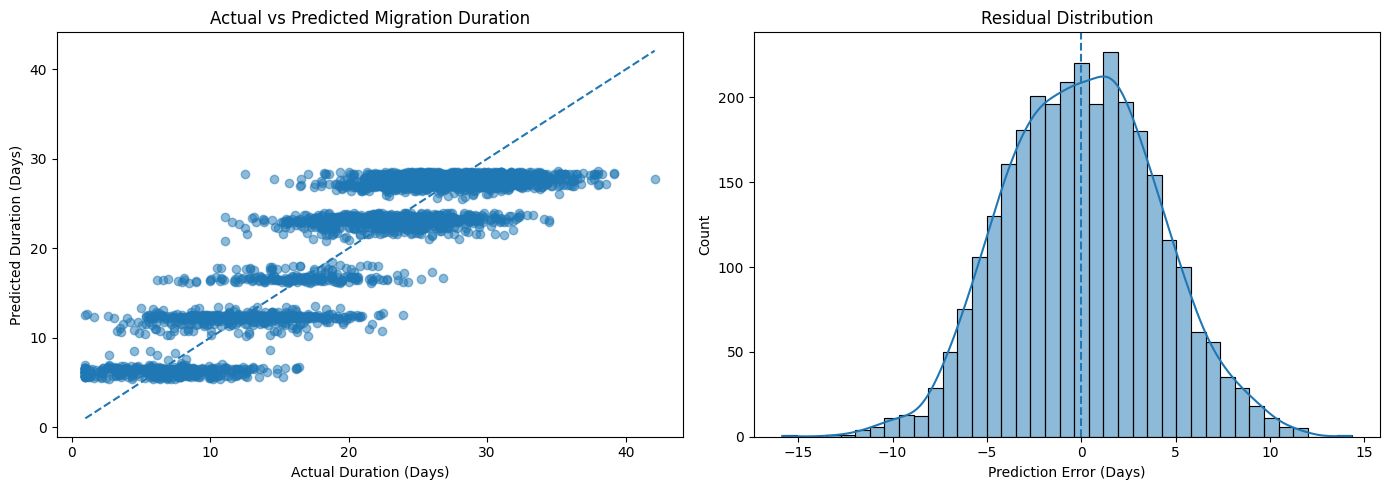

Mean Residual: 0.0425
Residual Std: 4.0154


In [53]:
# ============================================================
# DURATION REGRESSION - RESIDUAL ANALYSIS
# ============================================================

best_duration_model = grid_duration.best_estimator_

# Predict directly using raw test features
y_duration_test_pred = best_duration_model.predict(
    X_test_duration
)

residuals_duration = (
    y_duration_test - y_duration_test_pred
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(
    y_duration_test,
    y_duration_test_pred,
    alpha=0.5
)

min_val = min(
    y_duration_test.min(),
    y_duration_test_pred.min()
)

max_val = max(
    y_duration_test.max(),
    y_duration_test_pred.max()
)

axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

axes[0].set_title("Actual vs Predicted Migration Duration")
axes[0].set_xlabel("Actual Duration (Days)")
axes[0].set_ylabel("Predicted Duration (Days)")

# Residual distribution
sns.histplot(
    residuals_duration,
    kde=True,
    ax=axes[1]
)

axes[1].axvline(0, linestyle="--")
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Prediction Error (Days)")

plt.tight_layout()
plt.show()

print("Mean Residual:", round(residuals_duration.mean(), 4))
print("Residual Std:", round(residuals_duration.std(), 4))

,count,mean,std,min,median,max
Migration_Priority,,,,,,
High,7233,20.79,8.40,1.0,22.5,39.4
Immediate,4694,24.86,6.29,1.0,25.6,42.5
Low,1379,19.80,8.69,1.0,21.8,39.2
Medium,6694,18.25,9.35,1.0,18.9,43.1


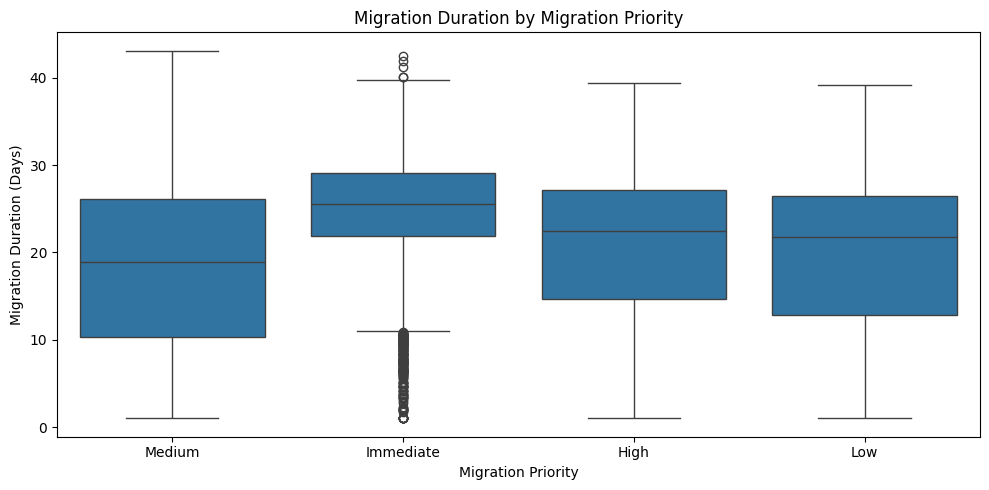

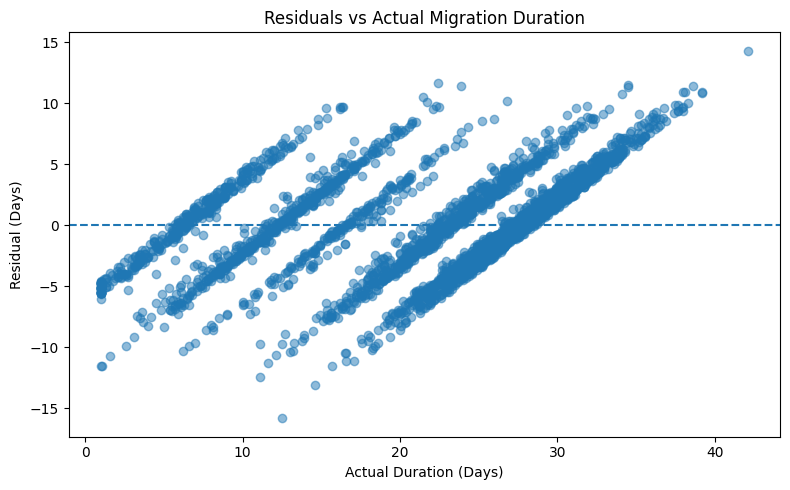

In [54]:
# ============================================================
# DURATION REGRESSION - TARGET AND PREDICTION DIAGNOSTICS
# ============================================================

# Actual duration by migration priority
duration_priority_analysis = (
    df_clean.groupby("Migration_Priority")[
        "Estimated_Migration_Duration_Days"
    ]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .round(2)
)

display(duration_priority_analysis)

# Actual duration distribution
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x="Migration_Priority",
    y="Estimated_Migration_Duration_Days"
)

plt.title("Migration Duration by Migration Priority")
plt.xlabel("Migration Priority")
plt.ylabel("Migration Duration (Days)")
plt.tight_layout()
plt.show()

# Residuals against actual duration
plt.figure(figsize=(8, 5))

plt.scatter(
    y_duration_test,
    residuals_duration,
    alpha=0.5
)

plt.axhline(0, linestyle="--")

plt.title("Residuals vs Actual Migration Duration")
plt.xlabel("Actual Duration (Days)")
plt.ylabel("Residual (Days)")

plt.tight_layout()
plt.show()

,count,mean,std,min,median,max
Predicted_Priority,,,,,,
High,1083,20.99,7.30,5.43,23.29,28.62
Immediate,657,25.18,4.60,5.40,27.25,28.59
Low,172,21.84,5.99,6.08,23.08,28.57
Medium,1088,17.69,8.47,5.40,16.70,28.62


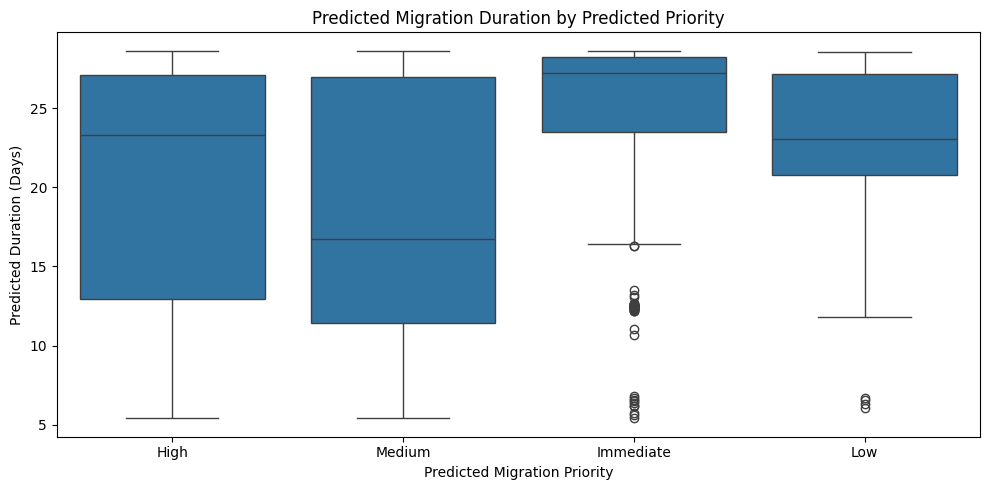

In [55]:
# ============================================================
# DURATION REGRESSION - PREDICTION BAND ANALYSIS
# ============================================================

duration_band_analysis = pd.DataFrame({
    "Actual_Duration": y_duration_test,
    "Predicted_Duration": y_duration_test_pred,
    "Predicted_Priority": X_duration_test["Migration_Priority"]
})

# Summary of predicted duration by predicted priority
band_summary = (
    duration_band_analysis
    .groupby("Predicted_Priority")["Predicted_Duration"]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .round(2)
)

display(band_summary)

# Visualize predictions by predicted priority
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=duration_band_analysis,
    x="Predicted_Priority",
    y="Predicted_Duration"
)

plt.title("Predicted Migration Duration by Predicted Priority")
plt.xlabel("Predicted Migration Priority")
plt.ylabel("Predicted Duration (Days)")

plt.tight_layout()
plt.show()

In [56]:
# ============================================================
# DURATION REGRESSION - PRIORITY-WISE ERROR ANALYSIS
# ============================================================

priority_error_analysis = duration_band_analysis.copy()

priority_error_analysis["Residual"] = (
    priority_error_analysis["Actual_Duration"] -
    priority_error_analysis["Predicted_Duration"]
)

priority_error_analysis["Absolute_Error"] = (
    priority_error_analysis["Residual"].abs()
)

priority_error_summary = (
    priority_error_analysis
    .groupby("Predicted_Priority")
    .agg(
        Samples=("Actual_Duration", "count"),
        Actual_Mean=("Actual_Duration", "mean"),
        Predicted_Mean=("Predicted_Duration", "mean"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean"),
        Actual_Std=("Actual_Duration", "std")
    )
    .round(3)
)

display(priority_error_summary)

,Samples,Actual_Mean,Predicted_Mean,MAE,Mean_Residual,Actual_Std
Predicted_Priority,,,,,,
High,1083,21.030,20.988,3.278,0.042,8.246
Immediate,657,25.358,25.181,3.287,0.177,6.046
Low,172,21.996,21.843,3.187,0.153,7.416
Medium,1088,17.636,17.692,3.202,-0.056,9.206


In [57]:
# ============================================================
# DURATION REGRESSION - FINAL EVALUATION
# ============================================================

# Use the best complete pipeline selected by GridSearchCV
best_duration_model = grid_duration.best_estimator_

# GridSearchCV with refit=True has already fitted the
# best pipeline on the complete training dataset.
# No additional fit is necessary.

# ------------------------------------------------------------
# VALIDATION EVALUATION
# ------------------------------------------------------------

y_val_pred_duration = best_duration_model.predict(
    X_val_duration
)

print("VALIDATION RESULTS")
print("-" * 40)

print("MAE:",
      round(mean_absolute_error(y_duration_val, y_val_pred_duration), 4))

print("RMSE:",
      round(np.sqrt(mean_squared_error(y_duration_val, y_val_pred_duration)), 4))

print("R²:",
      round(r2_score(y_duration_val, y_val_pred_duration), 4))


# ------------------------------------------------------------
# TEST EVALUATION
# ------------------------------------------------------------

y_test_pred_duration = best_duration_model.predict(
    X_test_duration
)

print("\nTEST RESULTS")
print("-" * 40)

print("MAE:",
      round(mean_absolute_error(y_duration_test, y_test_pred_duration), 4))

print("RMSE:",
      round(np.sqrt(mean_squared_error(y_duration_test, y_test_pred_duration)), 4))

print("R²:",
      round(r2_score(y_duration_test, y_test_pred_duration), 4))

VALIDATION RESULTS
----------------------------------------
MAE: 3.1556
RMSE: 3.9344
R²: 0.7985

TEST RESULTS
----------------------------------------
MAE: 3.2471
RMSE: 4.0149
R²: 0.784


In [58]:
# ============================================================
# FINAL QSECURE MODEL PACKAGE
# ============================================================

import joblib
from datetime import datetime, timezone

qsecure_model_package = {

    # -------------------------
    # 1. QUANTUM RISK SCORE
    # -------------------------

    "risk_model": final_model,
    "risk_preprocessor": preprocessor,
    "risk_selected_features": risk_selected_features,
    "risk_iqr_thresholds": thresholds,
    "risk_outlier_features": risk_outlier_features,

    # -------------------------
    # 2. PQC ALGORITHM
    # -------------------------
    "pqc_model": best_pqc_model,
    "pqc_preprocessor": preprocessor_pqc,
    "pqc_features": pqc_features,

    # -------------------------
    # 3. MIGRATION PRIORITY
    # -------------------------
    "priority_model": best_priority_model,
    "priority_preprocessor": preprocessor_priority,
    "priority_numerical_features": priority_numerical_features,
    "priority_categorical_features": priority_categorical_features,

    # -------------------------
    # 4. MIGRATION DURATION
    # -------------------------
    "duration_model": best_duration_model,
    "duration_preprocessor": duration_preprocessor,
    "duration_numerical_features": duration_numerical_features,
    "duration_categorical_features": duration_categorical_features,

    # -------------------------
    # FEATURE ENGINEERING
    # -------------------------
    "business_impact_mapping": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    },

    # -------------------------
    # MODEL METADATA
    # -------------------------
    "model_version": "QSecure_PQC_v1.0",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),

    "duration_metrics": {
      "test_mae": 3.2472,
      "test_rmse": 4.0149,
      "test_r2": 0.7840
  }
}

# -------------------------
# SAVE MODEL PACKAGE
# -------------------------

package_filename = "QSecure_PQC_Migration_Models.joblib"

joblib.dump(
    qsecure_model_package,
    package_filename,
    compress=3
)

print("Q-Secure model package saved successfully!")
print("File:", package_filename)
print("Model version:", qsecure_model_package["model_version"])
print("Number of package components:", len(qsecure_model_package))

Q-Secure model package saved successfully!
File: QSecure_PQC_Migration_Models.joblib
Model version: QSecure_PQC_v1.0
Number of package components: 20


In [59]:
# ============================================================
# QSECURE MODEL PACKAGE - INTEGRITY VERIFICATION
# ============================================================

import joblib
import os

# Load saved package
loaded_package = joblib.load(package_filename)

# Verify file
print("File exists:", os.path.exists(package_filename))
print("File size (MB):",
      round(os.path.getsize(package_filename) / (1024 * 1024), 2))

# Verify components
print("\nPACKAGE COMPONENT VERIFICATION")
print("-" * 45)

for component, value in loaded_package.items():
    status = "PASS" if value is not None else "FAIL"
    print(f"{component}: {status}")

# Verify model types
print("\nMODEL TYPE VERIFICATION")
print("-" * 45)

for key in [
    "risk_model",
    "pqc_model",
    "priority_model",
    "duration_model"
]:
    print(f"{key}: {type(loaded_package[key]).__name__}")

assert all(value is not None for value in loaded_package.values())

print("\nQ-Secure package integrity check completed!")

File exists: True
File size (MB): 0.51

PACKAGE COMPONENT VERIFICATION
---------------------------------------------
risk_model: PASS
risk_preprocessor: PASS
risk_selected_features: PASS
risk_iqr_thresholds: PASS
risk_outlier_features: PASS
pqc_model: PASS
pqc_preprocessor: PASS
pqc_features: PASS
priority_model: PASS
priority_preprocessor: PASS
priority_numerical_features: PASS
priority_categorical_features: PASS
duration_model: PASS
duration_preprocessor: PASS
duration_numerical_features: PASS
duration_categorical_features: PASS
business_impact_mapping: PASS
model_version: PASS
created_at_utc: PASS
duration_metrics: PASS

MODEL TYPE VERIFICATION
---------------------------------------------
risk_model: Ridge
pqc_model: Pipeline
priority_model: Pipeline
duration_model: Pipeline

Q-Secure package integrity check completed!


In [60]:

# ============================================================
# Q-SECURE - FINAL LOADED PACKAGE INFERENCE TEST
# ============================================================

import numpy as np
import pandas as pd
import joblib

loaded_package = joblib.load(package_filename)

sample_index = X_test.index[0]

# ------------------------------------------------------------
# 1. PREPARE ASSET FEATURES
# ------------------------------------------------------------

asset_input = X_test.loc[[sample_index]].copy()

# ------------------------------------------------------------
# 2. QUANTUM RISK PREDICTION
# ------------------------------------------------------------

risk_input = asset_input.loc[
    :,
    loaded_package["risk_selected_features"]
].copy()

# Apply saved IQR thresholds
for col in loaded_package["risk_outlier_features"]:

    limits = loaded_package["risk_iqr_thresholds"][col]

    risk_input[col] = risk_input[col].clip(
        lower=limits["lower"],
        upper=limits["upper"]
    )

risk_processed = loaded_package["risk_preprocessor"].transform(
    risk_input
)

predicted_risk = float(np.clip(
    loaded_package["risk_model"].predict(
        risk_processed
    )[0],
    0,
    100
))

# ------------------------------------------------------------
# 3. PQC RECOMMENDATION
# ------------------------------------------------------------

pqc_input = asset_input.loc[
    :, loaded_package["pqc_features"]
].copy()

pqc_input["Quantum_Risk_Score"] = predicted_risk

predicted_pqc = loaded_package["pqc_model"].predict(
    pqc_input
)[0]

# ------------------------------------------------------------
# 4. MIGRATION PRIORITY
# ------------------------------------------------------------

priority_input = pqc_input.copy()

priority_input["Recommended_PQC_Algorithm"] = predicted_pqc

predicted_priority = loaded_package["priority_model"].predict(
    priority_input
)[0]

# ------------------------------------------------------------
# 5. MIGRATION DURATION
# ------------------------------------------------------------

duration_input = priority_input.copy()

duration_input["Migration_Priority"] = predicted_priority

predicted_duration = loaded_package["duration_model"].predict(
    duration_input
)[0]

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

assert 0 <= predicted_risk <= 100
assert np.isfinite(predicted_duration)
assert predicted_duration > 0

# ------------------------------------------------------------
# 7. FINAL OUTPUT
# ------------------------------------------------------------

print("=" * 65)
print("Q-SECURE LOADED PACKAGE INFERENCE")
print("=" * 65)

print("Asset ID:", df.loc[sample_index, "Asset_ID"])
print("Quantum Risk Score:", round(predicted_risk, 2))
print("PQC Recommendation:", predicted_pqc)
print("Migration Priority:", predicted_priority)
print(
    "Estimated Migration Duration:",
    round(float(predicted_duration), 2),
    "days"
)

print("\nAll loaded-package inference checks passed.")


Q-SECURE LOADED PACKAGE INFERENCE
Asset ID: AST-006910
Quantum Risk Score: 68.1
PQC Recommendation: ML-KEM
Migration Priority: High
Estimated Migration Duration: 12.5 days

All loaded-package inference checks passed.


In [61]:
# ============================================================
# DOWNLOAD FINAL QSECURE MODEL
# ============================================================

from google.colab import files

files.download("QSecure_PQC_Migration_Models.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>